# Dubai Housing Regression and Time Series Analysis

This notebook analyzes the Dubai residential real-estate market using four combined datasets (Bayut listings, monthly area-level market stats, Dubai Land Department transactions, and off-plan project listings).

**Part 1 - Price Prediction:** After merging, cleaning, and encoding the data, several regression models are trained to predict log-transformed property price: Linear Regression (R² = 0.83), a baseline Lasso model, and a properly scaled + cross-validated Lasso (`LassoCV`), which resolves the baseline Lasso's under-tuned regularization and also reaches R² = 0.83 while performing genuine feature selection.

**Part 2 - Demand Forecasting:** A separate time series section forecasts Dubai property market activity (a demand proxy) 6 months ahead using Triple Exponential Smoothing and SARIMA, selecting whichever model performs better on held-out historical data, with full accuracy evaluation (MAE, RMSE, MAPE) and business recommendations.

*(See the detailed Project Overview below for full objectives and dataset descriptions.)*

---


House Price Prediction in Dubai (An Emerging Economy)
Project Overview

This project develops a house price prediction model for the Dubai real estate market using machine learning techniques. Dubai is one of the world's fastest-growing emerging economies, with a dynamic property market influenced by economic growth, infrastructure development, foreign investment, and government policies. Predicting house prices can assist buyers, investors, developers, and policymakers in making informed decisions.

Dataset Description

The analysis is based on four real estate datasets obtained from Bayut (UAE) and related market data sources. The datasets cover the period 2024–2026 and include detailed information on residential properties, area-level market statistics, off-plan developments, and other economic indicators.

Project Objectives

The primary objectives of this project are to:

1.Explore and understand the structure of the datasets.

2.Combine multiple datasets into a single analytical dataset.

3.Clean and preprocess the data for analysis.

4.Perform exploratory data analysis (EDA) through visualization.

5.Engineer meaningful features for machine learning.

6.Build predictive models for house price estimation.

7.Evaluate and compare the performance of different regression models.


In [1]:
#import relevant libraries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model
from sklearn import preprocessing
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings('ignore')

#### LOADING,MERGING AND UNDERSTANDING THE DATASETS WITH DATA PREPARATION

In [2]:
 # loading the datasets
df1 = pd.read_csv("bayut_selling_properties.csv")
df2 = pd.read_csv("area_prices_monthly.csv")
df3 = pd.read_csv("dubai_residential_data_2026.csv")
df4 = pd.read_csv("off_plan.csv")

In [10]:
# checking the first 5 rows of the data.
df1.head()

,price,price_category,type,beds,baths,address,furnishing,completion_status,post_date,average_rent,...,total_floors,total_building_area_sqft,elevators,area_name,city,country,Latitude,Longitude,purpose,year_month
0,1450000,Medium,Apartment,1,2,"The Bay, Business Bay, Dubai",Furnished,Ready,2024-04-15,0,...,0,0,0,business bay,Dubai,UAE,25.189427,55.264819,For Sale,2024-04
1,6600000,High,Townhouse,5,5,"Brookfield, DAMAC Hills, Dubai",Unfurnished,Ready,2024-04-15,0,...,0,0,0,damac hills,Dubai,UAE,25.028148,55.264246,For Sale,2024-04
2,4825000,High,Apartment,2,3,"Vida Residence Downtown, Downtown Dubai, Dubai",Unfurnished,Ready,2024-04-18,288929,...,56,1,11,downtown dubai,Dubai,UAE,25.186684,55.274705,For Sale,2024-04
3,980000,Average,Apartment,3,3,"Building 39, Al Reef Downtown, Al Reef, Abu Dhabi",Unfurnished,Ready,2024-01-03,73384,...,0,0,0,al reef,Abu Dhabi,UAE,24.466437,54.656891,For Sale,2024-01
4,2499999,Medium,Townhouse,3,4,"Nima, The Valley, Dubai",Furnished,Off-Plan,2024-02-28,0,...,0,0,0,the valley,Dubai,UAE,25.019221,55.447201,For Sale,2024-02


In [4]:
# checking the first 5 rows of the data.
df2.head()

,year_month,community,zone,is_freehold,secondary_price_per_sqft_usd,secondary_price_per_m2_usd,offplan_price_per_sqft_usd,rental_price_per_sqft_annual_usd,n_listings_secondary,n_listings_offplan,n_listings_rental,cbuae_base_rate_pct,avg_mortgage_rate_pct
0,2020-01,Palm Jumeirah,Palm Jumeirah,True,662,7126,752.0,43,26,72,111,1.5,3.0
1,2020-02,Palm Jumeirah,Palm Jumeirah,True,666,7167,728.0,43,64,78,45,1.5,3.0
2,2020-03,Palm Jumeirah,Palm Jumeirah,True,703,7564,762.0,46,144,71,99,1.5,3.0
3,2020-04,Palm Jumeirah,Palm Jumeirah,True,651,7002,727.0,42,146,69,14,0.4,1.9
4,2020-05,Palm Jumeirah,Palm Jumeirah,True,637,6852,676.0,41,147,28,83,0.4,1.9


In [5]:
# checking the first 5 rows of the data.
df3.head()

,INSTANCE_DATE,PROCEDURE_EN,IS_FREE_HOLD_EN,AREA_EN,PROP_SB_TYPE_EN,TRANS_VALUE,ACTUAL_AREA,ROOMS_EN,NEAREST_METRO_EN,NEAREST_MALL_EN,NEAREST_LANDMARK_EN,PROJECT_EN,price_per_sqm,size_category,value_band
0,2026-01-02,Sale,Free Hold,BURJ KHALIFA,Flat,2600000.0,140.95,2 B/R,Business Bay Metro Station,Dubai Mall,Downtown Dubai,BAHWAN TOWER,18446.26,Premium,High-End
1,2026-01-02,Sale,Free Hold,BURJ KHALIFA,Flat,2731642.0,134.46,2 B/R,Business Bay Metro Station,Dubai Mall,Downtown Dubai,Imperial Avenue,20315.65,Premium,High-End
2,2026-03-09,Sale,Free Hold,JUMEIRAH VILLAGE CIRCLE,Flat,620000.0,42.87,Studio,Nakheel Metro Station,Marina Mall,Sports City Swimming Academy,PANTHEON ELYSEE,14462.33,Compact,Entry
3,2026-03-06,Sale,Free Hold,JUMEIRAH VILLAGE CIRCLE,Flat,540000.0,36.86,Studio,Nakheel Metro Station,Marina Mall,Sports City Swimming Academy,NaN,14650.03,Compact,Entry
4,2026-03-06,Sale,Free Hold,INTERNATIONAL CITY PH 1,Flat,515000.0,66.50,1 B/R,Rashidiya Metro Station,City Centre Mirdif,NaN,NaN,7744.36,Mid-Size,Entry


In [6]:
# checking the first 5 rows of the data.
df4.head()

,id,date_listed,project_id,project_name,developer,developer_tier,community,zone,lat,lon,...,total_project_units,payment_plan,metro_station,metro_line,metro_distance_min,to_burj_khalifa_km,price_usd,price_per_sqft_usd,price_per_m2_usd,mortgage_rate_at_listing
0,O000001,2025-02-22,OP0015,Hartland Greens,Ellington,tier2,Dubai Production City,IMPZ,25.02540,55.25064,...,1500,10/90_post_handover,Dubai Internet City,Red,136,19.25,196600,293,3149,6.15
1,O000002,2021-03-19,OP0165,Aykon City,Sobha,tier1,The Meadows,Emirates Living,25.04572,55.17040,...,1500,50/50_post_handover,MRT-1,Red,51,19.83,3712600,621,6689,1.90
2,O000003,2021-02-16,OP0091,Beachgate,Nakheel,tier1,Jumeirah Park,Emirates Living,25.04807,55.17198,...,100,70/30,Abu Baker Al Siddique,Red,367,19.53,1521500,597,6424,1.90
3,O000004,2021-11-24,OP0165,Aykon City,Sobha,tier1,The Meadows,Emirates Living,25.04572,55.17040,...,1500,70/30,Al Furjan,Red,37,19.83,2976600,912,9816,1.90
4,O000005,2021-02-04,OP0130,Marina Vista,Dubai Properties,tier1,Liwan,Dubailand,25.06191,55.32871,...,400,60/40,Abu Hail,Red,306,16.01,112200,200,2154,1.90


## MERGING THE DATASETS

In [7]:
# ============================================
# STEP 1: Standardize text columns
# ============================================
# Convert area names to lowercase and remove extra spaces
# This ensures the names match during merging

df1["area_name"] = df1["area_name"].str.lower().str.strip()
df2["community"] = df2["community"].str.lower().str.strip()
df3["AREA_EN"] = df3["AREA_EN"].str.lower().str.strip()
df4["community"] = df4["community"].str.lower().str.strip()

In [8]:
# ============================================
# STEP 2: Convert date columns
# ============================================
# Convert text dates into datetime format

df1["post_date"] = pd.to_datetime(df1["post_date"])

df2["year_month"] = pd.to_datetime(df2["year_month"])

df3["INSTANCE_DATE"] = pd.to_datetime(df3["INSTANCE_DATE"])

df4["date_listed"] = pd.to_datetime(df4["date_listed"])

In [9]:
# ============================================
# STEP 3: Create a Year-Month column
# ============================================
# Extract only the year and month for matching monthly records

df1["year_month"] = df1["post_date"].dt.to_period("M").astype(str)

df2["year_month"] = df2["year_month"].dt.to_period("M").astype(str)


In [86]:
# ============================================
# STEP 4: Merge df1 and df2
# ============================================
# Merge property listings with monthly area statistics
# Matching is done using area name and year-month

merged = pd.merge(
    df1,
    df2,
    left_on=["area_name", "year_month"],      # Keys from df1
    right_on=["community", "year_month"],     # Keys from df2
    how="left"                                # Keep all records from df1
)

# Display the dataset size after merging
print("Shape after merging df1 and df2:")
print(merged.shape)

Shape after merging df1 and df2:
(41381, 35)


In [87]:
# ============================================
# STEP 5: Aggregate df3
# ============================================
# Calculate average statistics for each area
# This prevents duplicate rows during merging

area_stats = (
    df3.groupby("AREA_EN")
    .agg(
        avg_transaction_value=("TRANS_VALUE", "mean"),     # Average transaction price
        avg_price_per_sqm=("price_per_sqm", "mean"),       # Average price per square metre
        avg_area=("ACTUAL_AREA", "mean"),                  # Average property size
        total_transactions=("TRANS_VALUE", "count")        # Number of transactions
    )
    .reset_index()
)

# Preview the aggregated dataset
print(area_stats.head())

                  AREA_EN  avg_transaction_value  avg_price_per_sqm  \
0               al barari           2.410101e+06       19054.904175   
1         al barsha first           1.074231e+06       13105.384615   
2  al barshaa south third           8.433333e+05       10503.190000   
3               al furjan           1.241129e+06       14274.803934   
4        al khail heights           8.890136e+05       10149.264821   

     avg_area  total_transactions  
0  124.256311                 103  
1   82.243077                  13  
2   80.323333                   3  
3   88.327473                 455  
4   90.276786                  56  


In [89]:
# ============================================
# STEP 7: Aggregate df4
# ============================================
# Calculate average off-plan statistics for each community

offplan_stats = (
    df4.groupby("community")
    .agg(
        avg_offplan_price=("price_usd", "mean"),                  # Average project price
        avg_offplan_price_sqft=("price_per_sqft_usd", "mean"),    # Average price per sqft
        avg_offplan_price_m2=("price_per_m2_usd", "mean"),        # Average price per square metre
        avg_mortgage_listing=("mortgage_rate_at_listing", "mean"),# Average mortgage rate
        total_projects=("project_id", "count")                    # Number of projects
    )
    .reset_index()
)

# Preview the aggregated dataset
print(offplan_stats.head())

           community  avg_offplan_price  avg_offplan_price_sqft  \
0          al furjan       4.647104e+05              440.929412   
1            al reem       2.657357e+06              634.218310   
2    arabian ranches       3.527603e+06              872.413793   
3  arabian ranches 2       3.707836e+06              892.688172   
4  arabian ranches 3       3.895521e+06              945.338235   

   avg_offplan_price_m2  avg_mortgage_listing  total_projects  
0           4746.014118              4.694706             425  
1           6827.056338              4.945775             142  
2           9390.620690              5.049138              58  
3           9609.139785              4.633692             279  
4          10175.426471              5.249265              68  


In [90]:
# ============================================
# STEP 8: Merge df4
# ============================================
# Add off-plan market information

merged = merged.merge(
    offplan_stats,
    left_on="area_name",
    right_on="community",
    how="left"
)

# Display the final dataset size
print("Final Dataset Shape:")
print(merged.shape)

Final Dataset Shape:
(41381, 46)


In [91]:
# ============================================
# STEP 9: Save the final datasets
# ============================================
# Save the merged datasets for further analysis

merged.to_csv("Dubai_House_Price_Final_Dataset.csv", index=False)

# Confirm successful saving

print("\nDataset saved successfully!")


Dataset saved successfully!


In [88]:
# ============================================
# STEP 6: Merge df3
# ============================================
# Add area transaction statistics to the merged dataset

merged = merged.merge(
    area_stats,
    left_on="area_name",
    right_on="AREA_EN",
    how="left"
)

# Display the dataset size after merging
print("Shape after merging df3:")
print(merged.shape)

Shape after merging df3:
(41381, 40)


In [92]:
# showing the first five rows of the merged datasets.
merged.head()   

,price,price_category,type,beds,baths,address,furnishing,completion_status,post_date,average_rent,...,avg_transaction_value,avg_price_per_sqm,avg_area,total_transactions,community_y,avg_offplan_price,avg_offplan_price_sqft,avg_offplan_price_m2,avg_mortgage_listing,total_projects
0,1450000,Medium,Apartment,1,2,"The Bay, Business Bay, Dubai",Furnished,Ready,2024-04-15,0,...,2.297005e+06,22560.114327,100.365218,1650.0,business bay,7.219907e+05,641.078292,6900.793594,4.744840,281.0
1,6600000,High,Townhouse,5,5,"Brookfield, DAMAC Hills, Dubai",Unfurnished,Ready,2024-04-15,0,...,9.849267e+05,14568.697078,69.039877,243.0,damac hills,1.001183e+06,486.295775,5234.577465,4.656338,71.0
2,4825000,High,Apartment,2,3,"Vida Residence Downtown, Downtown Dubai, Dubai",Unfurnished,Ready,2024-04-18,288929,...,NaN,NaN,NaN,NaN,downtown dubai,1.061731e+06,963.986486,10375.966216,4.988514,148.0
3,980000,Average,Apartment,3,3,"Building 39, Al Reef Downtown, Al Reef, Abu Dhabi",Unfurnished,Ready,2024-01-03,73384,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2499999,Medium,Townhouse,3,4,"Nima, The Valley, Dubai",Furnished,Off-Plan,2024-02-28,0,...,NaN,NaN,NaN,NaN,the valley,1.602527e+06,394.512690,4246.456853,4.689848,197.0


In [93]:
# checking the statistical summary.
merged.describe()

,price,beds,baths,post_date,average_rent,year_of_completion,total_parking_spaces,total_floors,total_building_area_sqft,elevators,...,avg_mortgage_rate_pct,avg_transaction_value,avg_price_per_sqm,avg_area,total_transactions,avg_offplan_price,avg_offplan_price_sqft,avg_offplan_price_m2,avg_mortgage_listing,total_projects
count,4.138100e+04,41381.000000,41381.000000,41381,4.138100e+04,41381.000000,41381.000000,41381.000000,41381.000000,41381.000000,...,19380.000000,1.269400e+04,12694.000000,12694.000000,12694.000000,1.785200e+04,17852.000000,17852.000000,17852.000000,17852.000000
mean,3.788624e+06,2.190957,3.007540,2024-02-26 15:39:23.258500608,9.292880e+04,681.112491,172.559073,13.212126,142.931273,2.304463,...,6.888493,2.436170e+06,22772.728900,104.189540,706.274539,1.423741e+06,761.890602,8200.987911,4.832602,203.075790
min,0.000000e+00,0.000000,0.000000,2021-12-15 00:00:00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.900000,7.039330e+05,7972.016000,53.268578,5.000000,2.442720e+05,214.260870,2306.534161,4.440244,45.000000
25%,1.100000e+06,1.000000,2.000000,2024-02-06 00:00:00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,...,6.900000,1.103107e+06,14568.697078,80.571893,266.000000,7.219907e+05,533.511111,5742.711111,4.744840,135.000000
50%,2.000000e+06,2.000000,3.000000,2024-03-18 00:00:00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,...,6.900000,2.162533e+06,22560.114327,100.365218,517.000000,1.061731e+06,802.181818,8634.363636,4.786090,164.000000
75%,3.600000e+06,3.000000,4.000000,2024-04-15 00:00:00,1.243790e+05,2012.000000,198.000000,22.000000,211.000000,4.000000,...,6.900000,2.824009e+06,28344.918481,108.334752,981.000000,1.953822e+06,963.986486,10375.966216,4.988514,281.000000
max,4.825000e+08,11.000000,11.000000,2024-04-25 00:00:00,2.807952e+07,2024.000000,2929.000000,89.000000,997.000000,42.000000,...,6.900000,6.185711e+06,36227.966438,213.337500,1650.000000,6.705213e+06,1639.794737,17650.536842,5.249265,501.000000
std,8.482870e+06,1.567855,1.785553,NaN,2.503703e+05,953.886883,353.899074,20.298365,248.719849,4.440953,...,0.150756,1.562702e+06,7803.383072,32.610071,537.735603,1.004742e+06,309.955442,3336.374741,0.151246,104.794434


In [94]:
#displaying the summary of the dataset
merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41381 entries, 0 to 41380
Data columns (total 46 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   price                             41381 non-null  int64         
 1   price_category                    41381 non-null  object        
 2   type                              41381 non-null  object        
 3   beds                              41381 non-null  int64         
 4   baths                             41381 non-null  int64         
 5   address                           41381 non-null  object        
 6   furnishing                        41381 non-null  object        
 7   completion_status                 41381 non-null  object        
 8   post_date                         41381 non-null  datetime64[ns]
 9   average_rent                      41381 non-null  int64         
 10  building_name                     41381 non-nu

In [95]:
 # checking for missing values in the data.
merged.isnull().sum()

price                                   0
price_category                          0
type                                    0
beds                                    0
baths                                   0
address                                 0
furnishing                              0
completion_status                       0
post_date                               0
average_rent                            0
building_name                           0
year_of_completion                      0
total_parking_spaces                    0
total_floors                            0
total_building_area_sqft                0
elevators                               0
area_name                               0
city                                    0
country                                 0
Latitude                               18
Longitude                              18
purpose                                 0
year_month                              0
community_x                       

In [96]:
#checking for duplicated rows
merged.duplicated().sum()

0

### INITIAL VISUALIZATION OF DATA

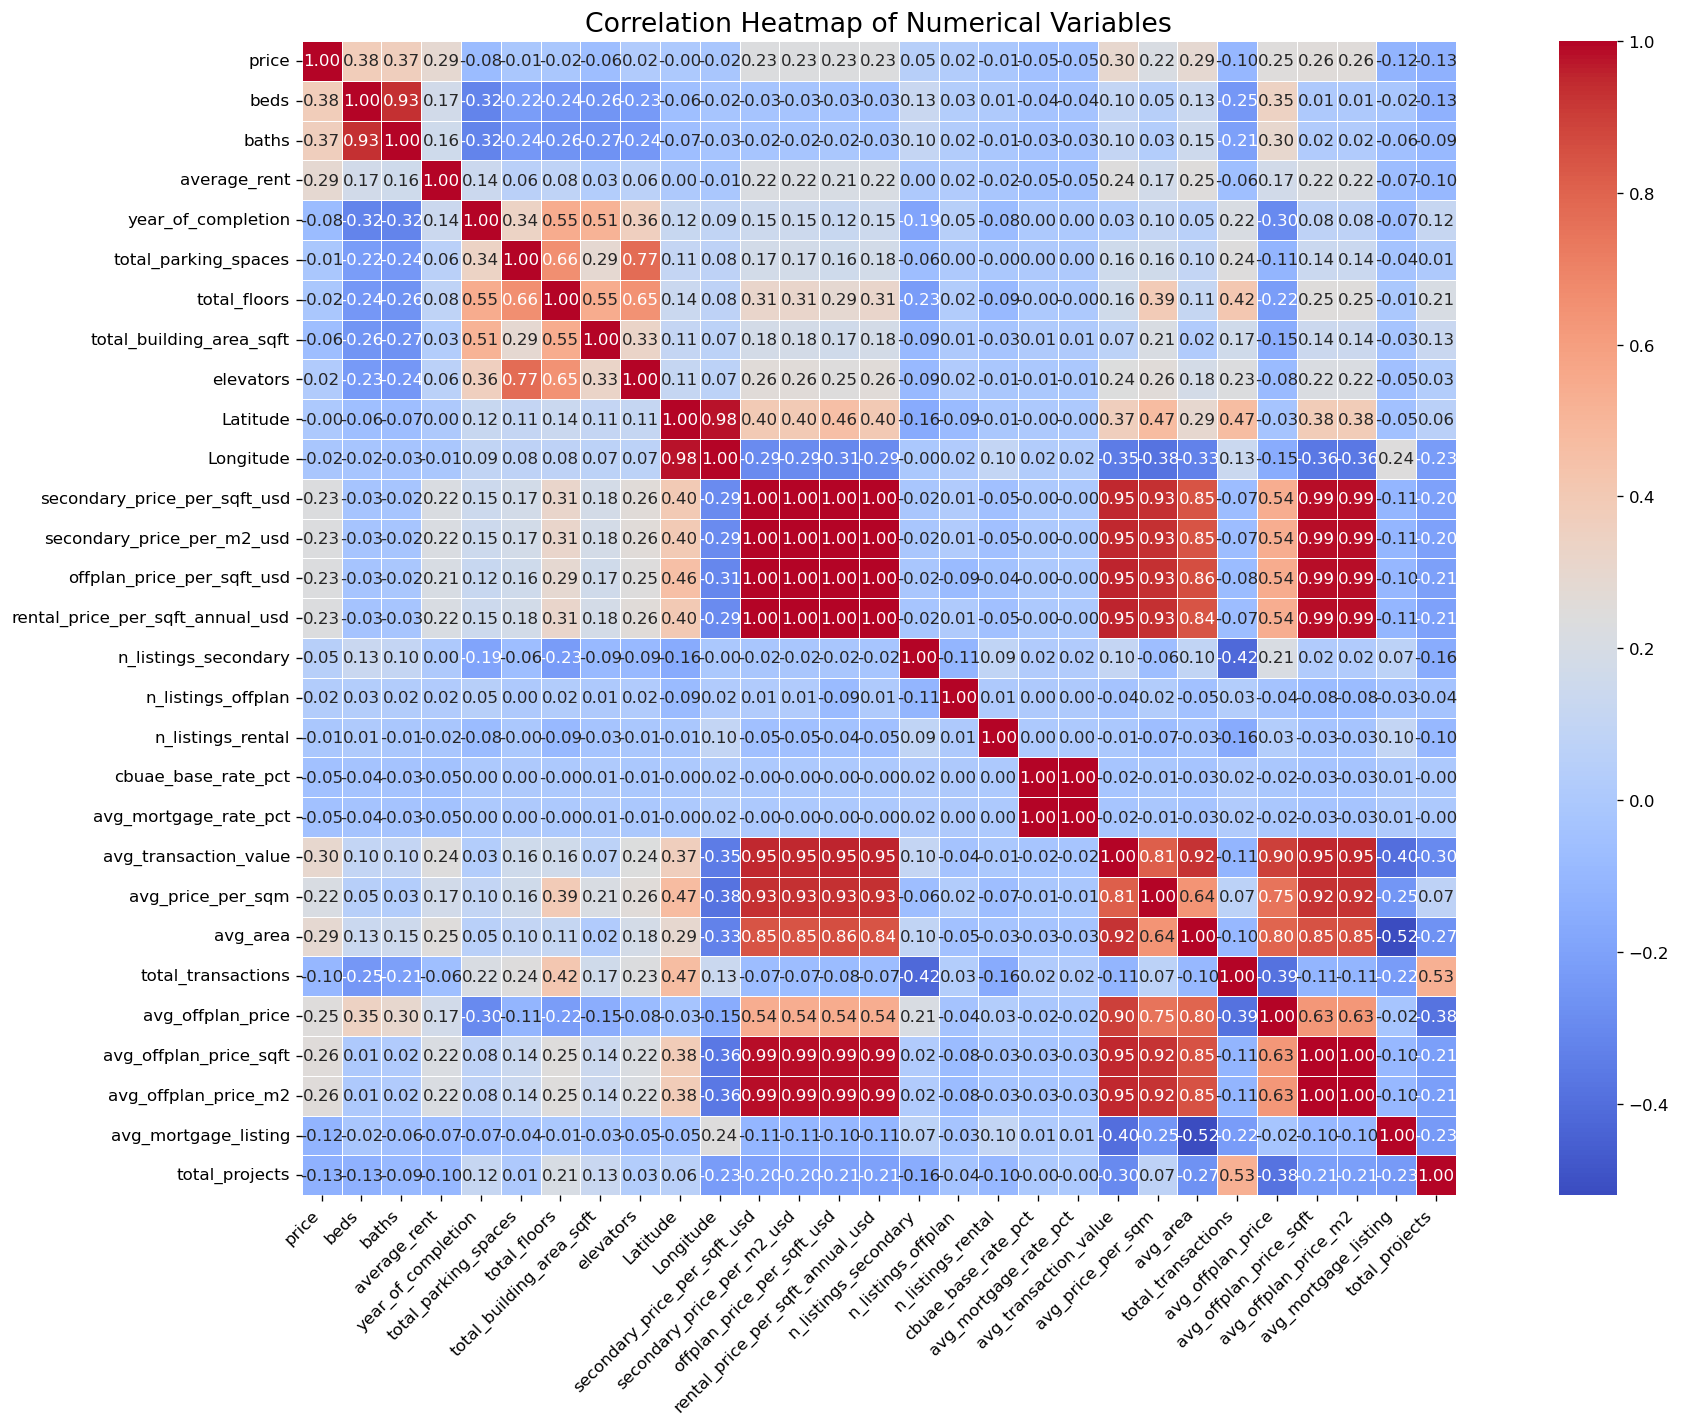

In [97]:
# Correlation heatmap for for numerical columns.

# ============================================
# Select only numerical columns
# ============================================
numeric_df = merged.select_dtypes(include=["number"])

# ============================================
# Calculate the correlation matrix
# ============================================
corr_matrix = numeric_df.corr()

# ============================================
# Plot the correlation heatmap
# ============================================
plt.figure(figsize=(18, 12), dpi=120)

sns.heatmap(
    corr_matrix,
    annot=True,          # Display correlation values
    cmap="coolwarm",     # Blue = negative, Red = positive
    fmt=".2f",           # Show values to 2 decimal places
    linewidths=0.5,
    square=True
)

plt.title("Correlation Heatmap of Numerical Variables", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

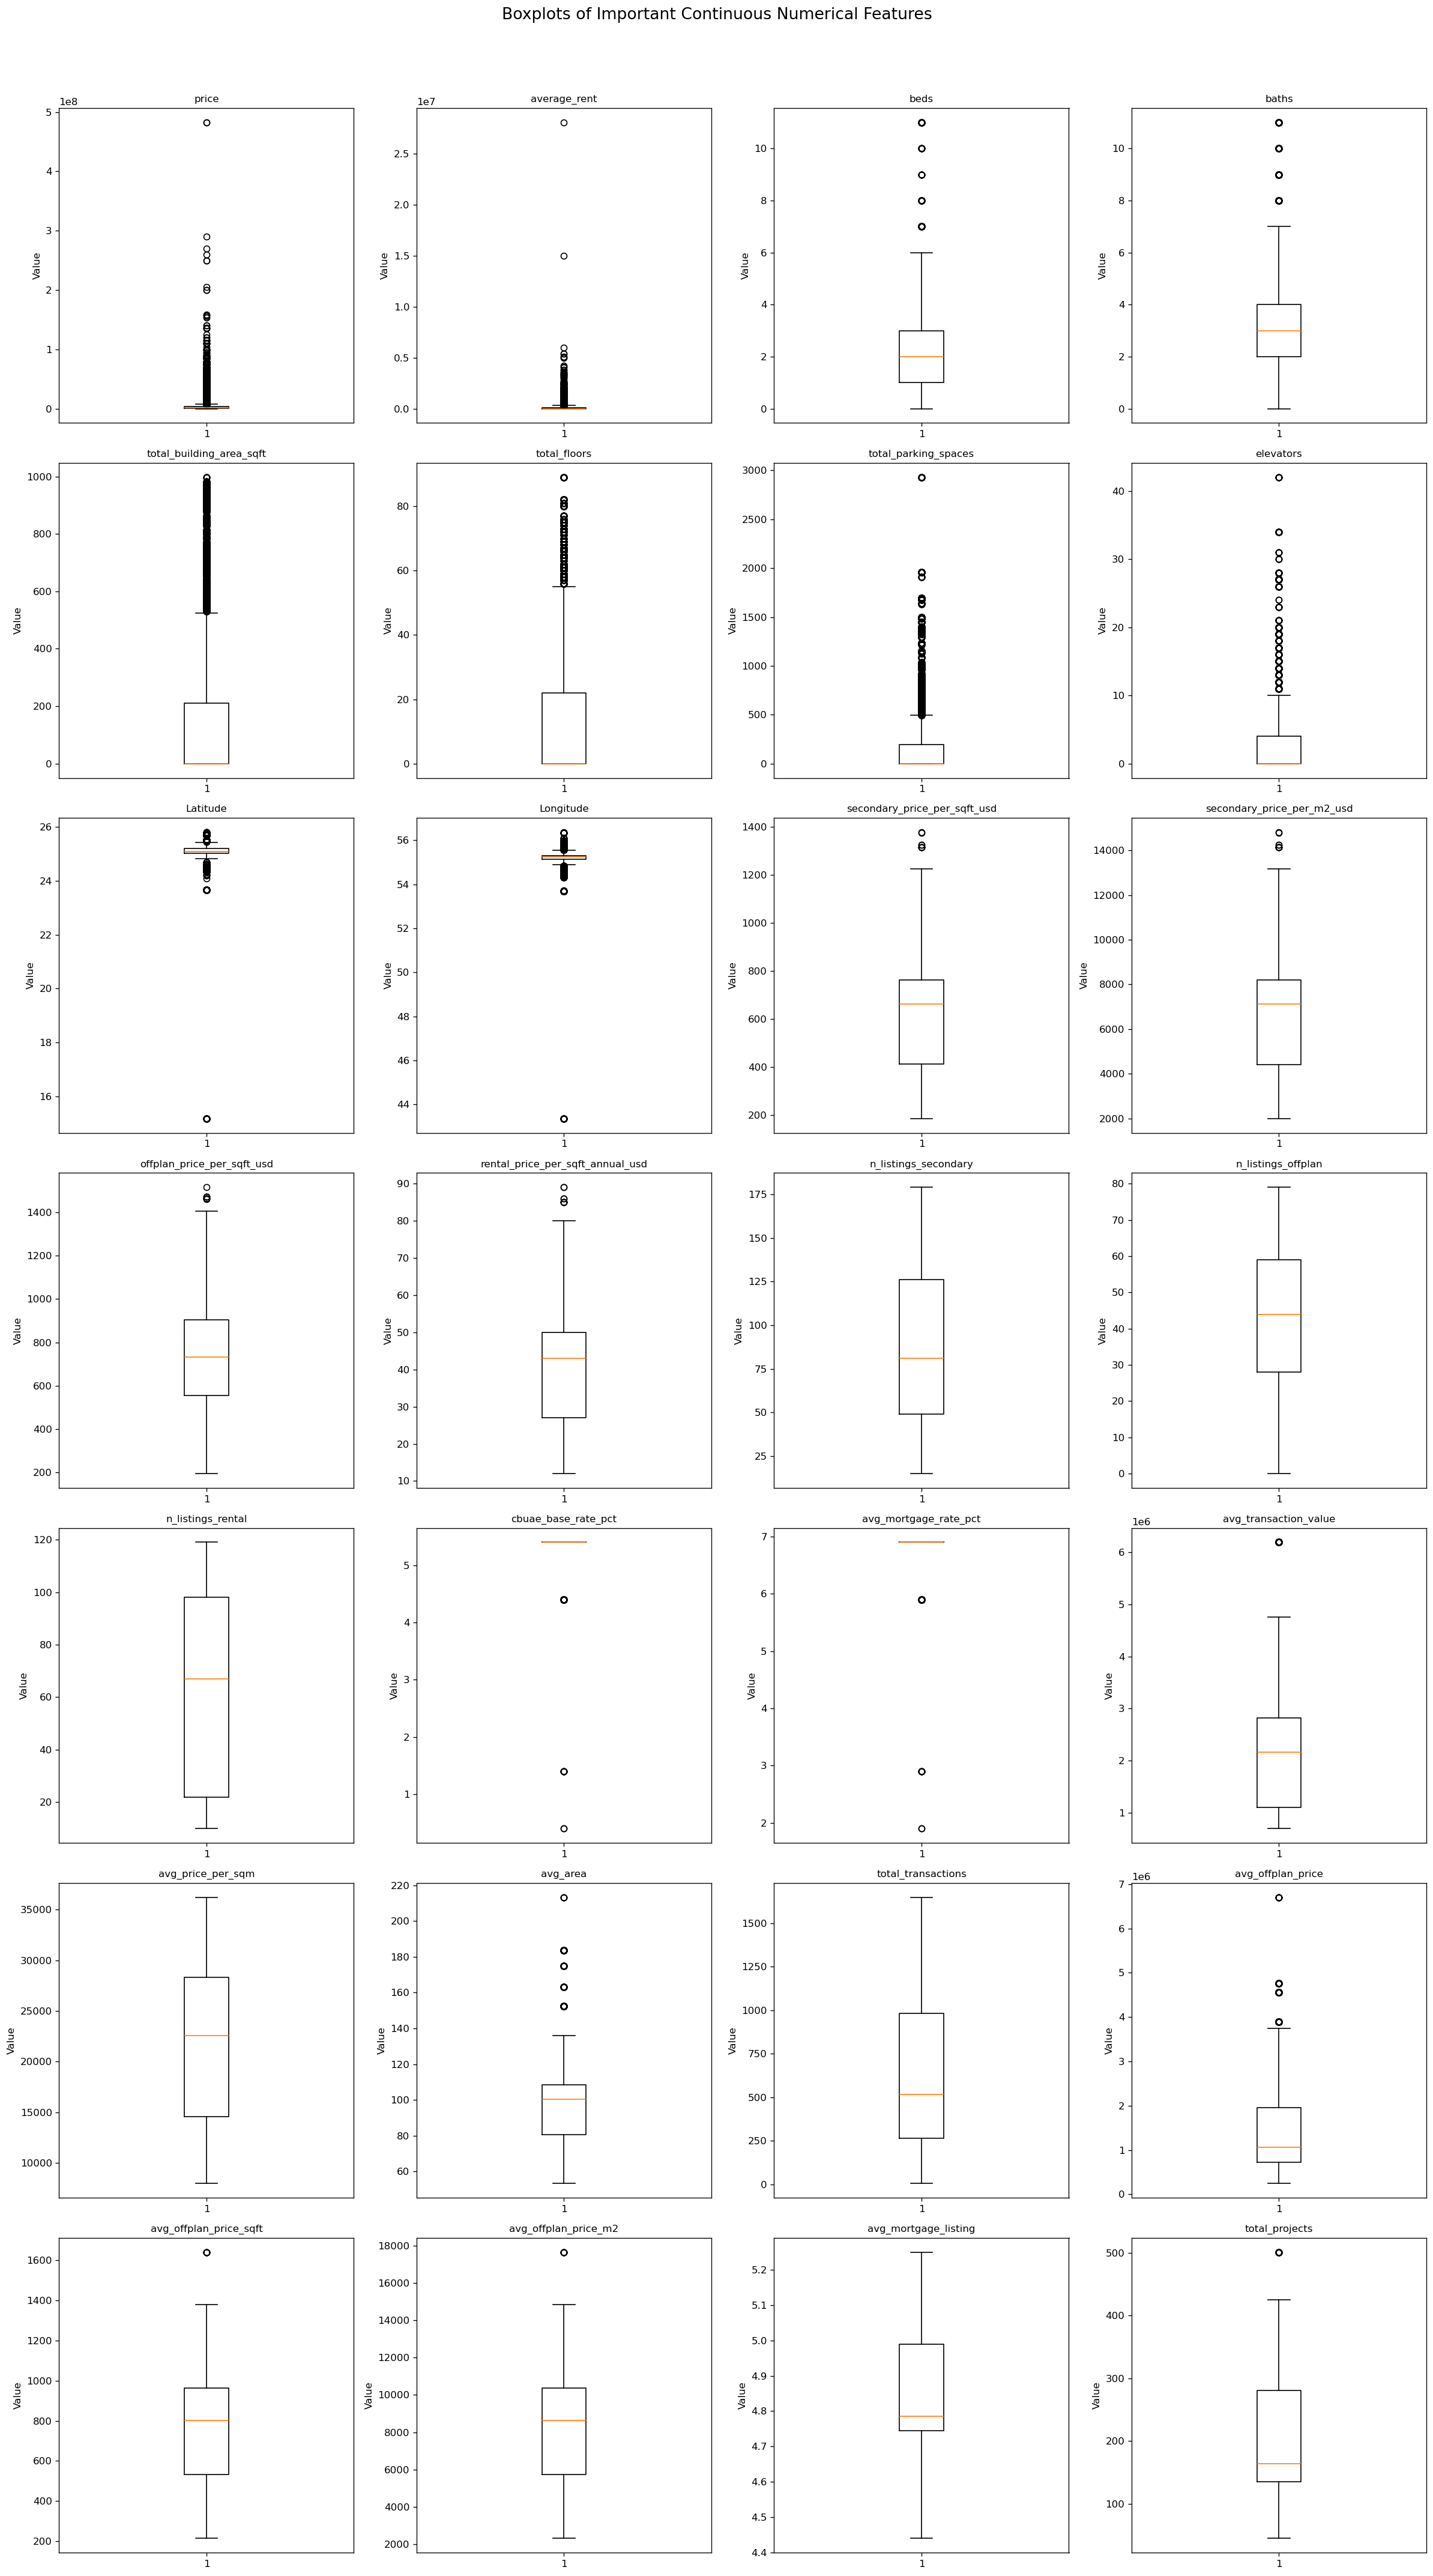

In [98]:
# Boxplot for selected features.

# ============================================
# Important continuous numerical features
# ============================================
continuous_cols = [
    "price",
    "average_rent",
    "beds",
    "baths",
    "total_building_area_sqft",
    "total_floors",
    "total_parking_spaces",
    "elevators",
    "Latitude",
    "Longitude",
    "secondary_price_per_sqft_usd",
    "secondary_price_per_m2_usd",
    "offplan_price_per_sqft_usd",
    "rental_price_per_sqft_annual_usd",
    "n_listings_secondary",
    "n_listings_offplan",
    "n_listings_rental",
    "cbuae_base_rate_pct",
    "avg_mortgage_rate_pct",
    "avg_transaction_value",
    "avg_price_per_sqm",
    "avg_area",
    "total_transactions",
    "avg_offplan_price",
    "avg_offplan_price_sqft",
    "avg_offplan_price_m2",
    "avg_mortgage_listing",
    "total_projects"
]

# Keep only columns that actually exist in the merged dataset
continuous_cols = [col for col in continuous_cols if col in merged.columns]

# ============================================
# Create subplots
# ============================================
n_cols = 4                                  # Number of plots per row
n_rows = (len(continuous_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, 5 * n_rows),
    dpi=120
)

# Flatten axes array for easy looping
axes = axes.flatten()

# ============================================
# Plot boxplots
# ============================================
for ax, col in zip(axes, continuous_cols):
    ax.boxplot(merged[col].dropna())
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("Value")

# Remove any unused subplot spaces
for ax in axes[len(continuous_cols):]:
    fig.delaxes(ax)

# ============================================
# Improve layout
# ============================================
plt.suptitle(
    "Boxplots of Important Continuous Numerical Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

# ============================================
# Display figure
# ============================================
plt.show()


In [99]:
# Finding the number of outliers 
# ============================================
# Select all numerical columns
# ============================================
numeric_cols = merged.select_dtypes(include=["number"]).columns

# ============================================
# Create an empty list to store results
# ============================================
outlier_summary = []

# ============================================
# Loop through each numerical column
# ============================================
for col in numeric_cols:

    # Calculate the first quartile (25%)
    Q1 = merged[col].quantile(0.25)

    # Calculate the third quartile (75%)
    Q3 = merged[col].quantile(0.75)

    # Calculate the Interquartile Range
    IQR = Q3 - Q1

    # Calculate the lower and upper limits
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Find all outliers
    outliers = merged[
        (merged[col] < lower_limit) |
        (merged[col] > upper_limit)
    ]

    # Store the results
    outlier_summary.append({
        "Feature": col,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "Lower Limit": round(lower_limit, 2),
        "Upper Limit": round(upper_limit, 2),
        "Number of Outliers": len(outliers),
        "Percentage": round((len(outliers) / len(merged)) * 100, 2)
    })

# ============================================
# Convert results into a DataFrame
# ============================================
outlier_df = pd.DataFrame(outlier_summary)

# Display the results
print(outlier_df)

# Optional: Sort by the number of outliers
outlier_df = outlier_df.sort_values(
    by="Number of Outliers",
    ascending=False
)

print("\nOutlier Summary (Highest to Lowest)")
print(outlier_df)

                             Feature          Q1          Q3         IQR  \
0                              price  1100000.00  3600000.00  2500000.00   
1                               beds        1.00        3.00        2.00   
2                              baths        2.00        4.00        2.00   
3                       average_rent        0.00   124379.00   124379.00   
4                 year_of_completion        0.00     2012.00     2012.00   
5               total_parking_spaces        0.00      198.00      198.00   
6                       total_floors        0.00       22.00       22.00   
7           total_building_area_sqft        0.00      211.00      211.00   
8                          elevators        0.00        4.00        4.00   
9                           Latitude       25.03       25.19        0.16   
10                         Longitude       55.14       55.31        0.17   
11      secondary_price_per_sqft_usd      411.00      763.00      352.00   
12        se

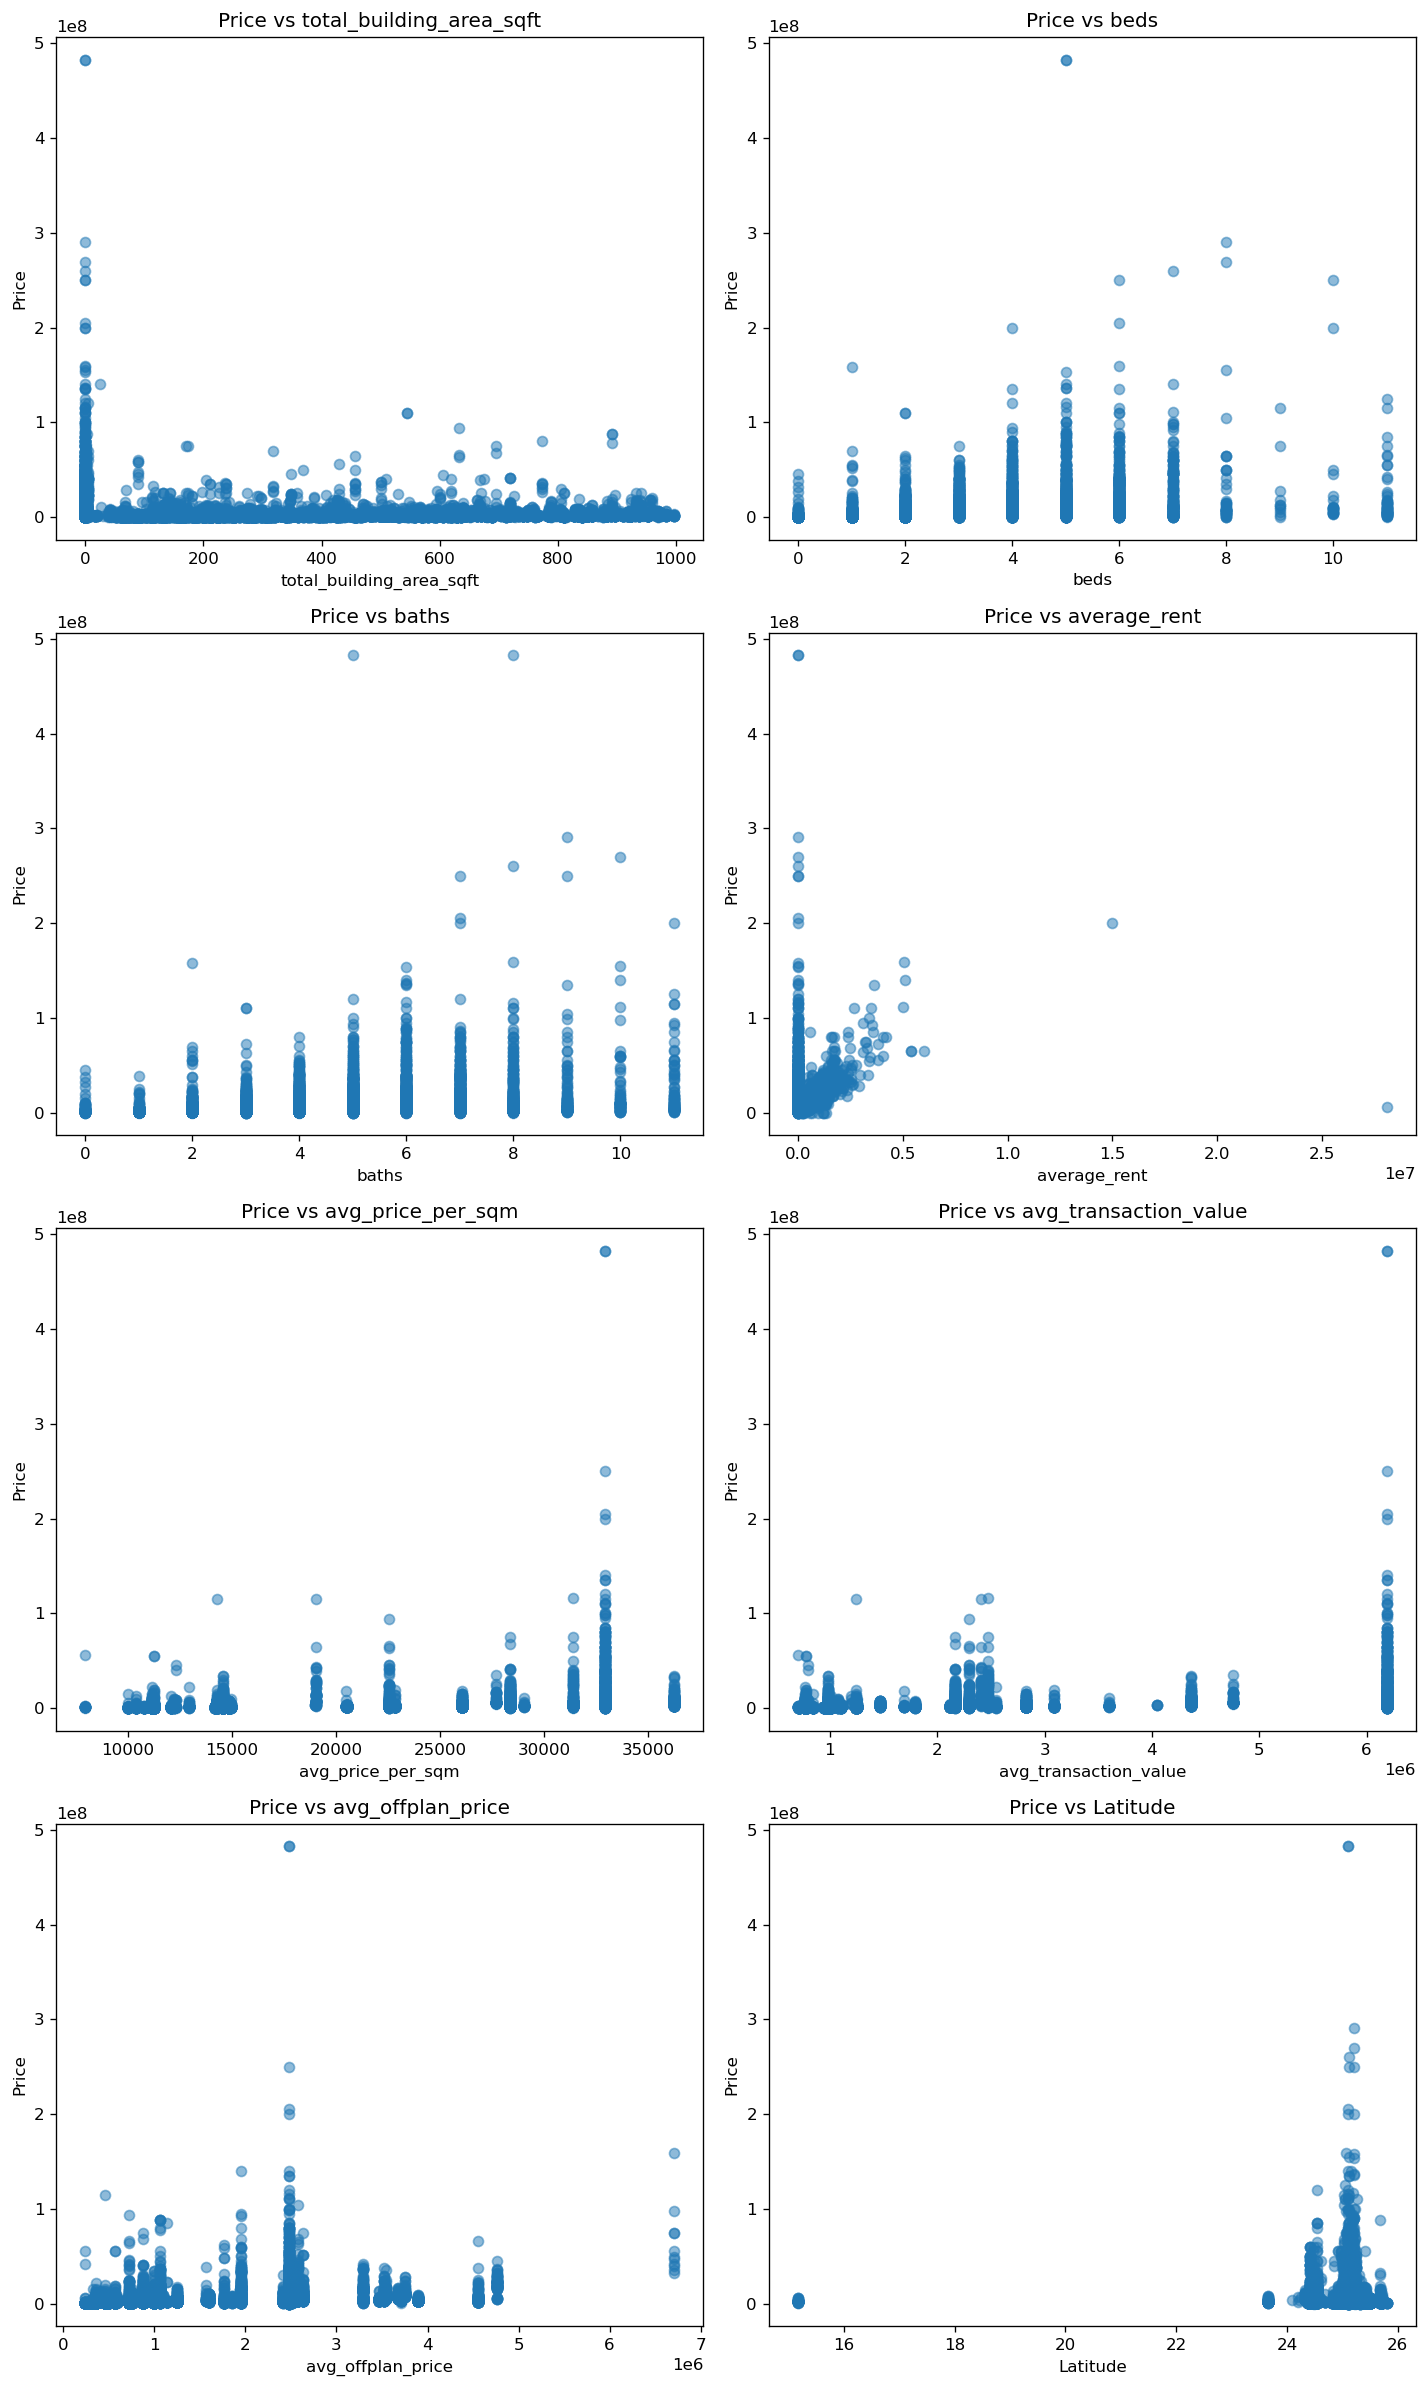

In [100]:
# Scatter plot for selected features.
# ============================================
# Features to compare with price
# ============================================
features = [
    "total_building_area_sqft",
    "beds",
    "baths",
    "average_rent",
    "avg_price_per_sqm",
    "avg_transaction_value",
    "avg_offplan_price",
    "Latitude"
]

# Keep only columns that exist
features = [col for col in features if col in merged.columns]

# ============================================
# Create subplots
# ============================================
n_cols = 2
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, 5 * n_rows),
    dpi=120,
)

axes = axes.flatten()

# ============================================
# Plot scatterplots
# ============================================
for ax, feature in zip(axes, features):

    ax.scatter(
        merged[feature],
        merged["price"],
        alpha=0.5
    )

    ax.set_title(f"Price vs {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Price")

# Remove unused subplots
for ax in axes[len(features):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()


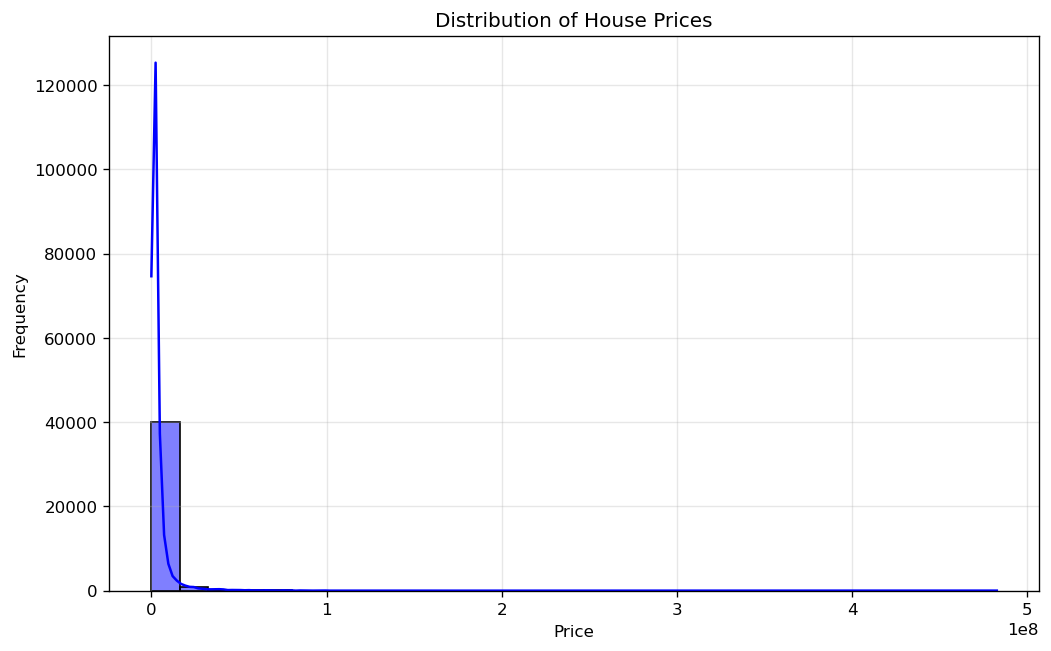

In [101]:
# ============================================
# Ploting histogram to check the skewness of price
# ============================================
plt.figure(figsize=(10,6), dpi=120)

sns.histplot(
    data=merged,
    x="price",
    bins=30,          # Number of histogram bins
    kde=True,         # Add density curve
    color="blue",
    edgecolor="black"
)

# ============================================
#  titles and labels
# ============================================
plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)

plt.show()

### DATA CLEANING

In [102]:
# HANDLING MISSING VALUES IN THE DATASET.

# Count missing values in each column
print(merged.isnull().sum())

# Percentage of missing values
missing_percent = (merged.isnull().sum() / len(merged)) * 100

print(missing_percent.sort_values(ascending=False))

price                                   0
price_category                          0
type                                    0
beds                                    0
baths                                   0
address                                 0
furnishing                              0
completion_status                       0
post_date                               0
average_rent                            0
building_name                           0
year_of_completion                      0
total_parking_spaces                    0
total_floors                            0
total_building_area_sqft                0
elevators                               0
area_name                               0
city                                    0
country                                 0
Latitude                               18
Longitude                              18
purpose                                 0
year_month                              0
community_x                       

In [103]:
# ============================================
# Filling missing numerical values with the median
# ============================================

numeric_cols = merged.select_dtypes(include=["number"]).columns

for col in numeric_cols:
    merged[col] = merged[col].fillna(merged[col].median())

In [104]:
# ============================================
# Filling missing categorical values with the mode
# ============================================

categorical_cols = merged.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    merged[col] = merged[col].fillna(merged[col].mode()[0])

In [105]:
print("Remaining Missing Values")
print(merged.isnull().sum())

Remaining Missing Values
price                               0
price_category                      0
type                                0
beds                                0
baths                               0
address                             0
furnishing                          0
completion_status                   0
post_date                           0
average_rent                        0
building_name                       0
year_of_completion                  0
total_parking_spaces                0
total_floors                        0
total_building_area_sqft            0
elevators                           0
area_name                           0
city                                0
country                             0
Latitude                            0
Longitude                           0
purpose                             0
year_month                          0
community_x                         0
zone                                0
is_freehold              

In [106]:
#HANDLING OUTLIERS
# ============================================
# Features to cap using the IQR method
# ============================================
cols_to_cap = ["total_building_area_sqft","average_rent",
    "total_parking_spaces",
    "total_floors"
]

# ============================================
# Cap outliers
# ============================================
for col in cols_to_cap:

    Q1 = merged[col].quantile(0.25)
    Q3 = merged[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    merged[col] = merged[col].clip(lower=lower, upper=upper)

print("Outliers capped successfully.")

Outliers capped successfully.


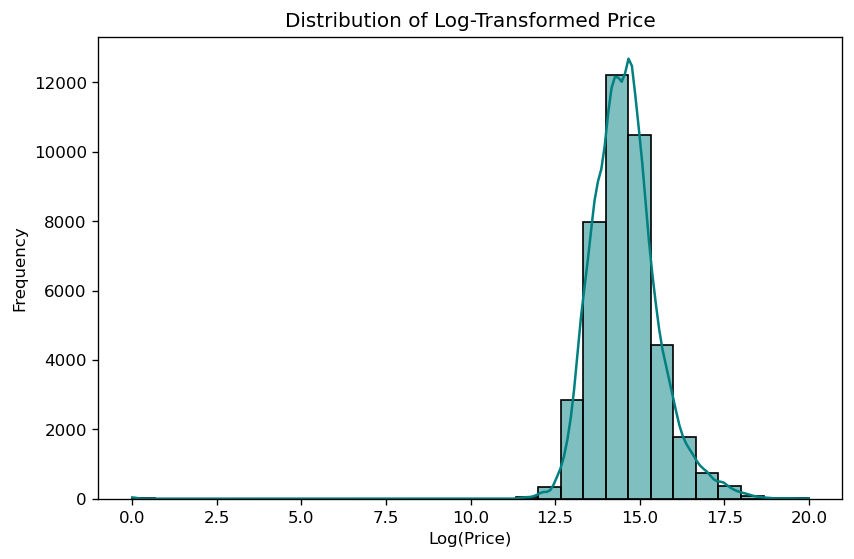

In [107]:
# Log transformation of price to reduce skewness. 

merged["log_price"] = np.log1p(merged["price"])
# visualize the new distribution after log transform.

plt.figure(figsize=(8,5), dpi=120)

sns.histplot(
    merged["log_price"],
    bins=30,
    kde=True,
    color="teal"
)

plt.title("Distribution of Log-Transformed Price")
plt.xlabel("Log(Price)")
plt.ylabel("Frequency")

plt.show()


In [108]:
# Verifying the result of the IQR summary to confirm effect.

numeric_cols = merged.select_dtypes(include=["number"]).columns

for col in numeric_cols:

    Q1 = merged[col].quantile(0.25)
    Q3 = merged[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = merged[
        (merged[col] < lower) |
        (merged[col] > upper)
    ]

    print(f"{col}: {len(outliers)} outliers")

price: 3880 outliers
beds: 349 outliers
baths: 741 outliers
average_rent: 0 outliers
year_of_completion: 0 outliers
total_parking_spaces: 0 outliers
total_floors: 0 outliers
total_building_area_sqft: 0 outliers
elevators: 2248 outliers
Latitude: 6965 outliers
Longitude: 8814 outliers
secondary_price_per_sqft_usd: 19070 outliers
secondary_price_per_m2_usd: 19096 outliers
offplan_price_per_sqft_usd: 18685 outliers
rental_price_per_sqft_annual_usd: 18086 outliers
n_listings_secondary: 18884 outliers
n_listings_offplan: 18025 outliers
n_listings_rental: 19174 outliers
cbuae_base_rate_pct: 170 outliers
avg_mortgage_rate_pct: 170 outliers
avg_transaction_value: 10582 outliers
avg_price_per_sqm: 10271 outliers
avg_area: 10271 outliers
total_transactions: 12240 outliers
avg_offplan_price: 15788 outliers
avg_offplan_price_sqft: 15740 outliers
avg_offplan_price_m2: 15740 outliers
avg_mortgage_listing: 17528 outliers
total_projects: 17398 outliers
log_price: 1006 outliers


In [109]:
# HANDLING DUPLICATES
# Count duplicate rows
duplicates = merged.duplicated().sum()

print("Number of duplicate rows:", duplicates)


# Display duplicate rows
duplicate_rows = merged[merged.duplicated()]

print(duplicate_rows)

# Remove duplicate rows
merged = merged.drop_duplicates()

print("Duplicates removed successfully.")


print("Remaining duplicates:", merged.duplicated().sum())

Number of duplicate rows: 3
          price price_category       type  beds  baths  \
26582   5500000           High  Apartment     2      3   
30773  20000000           High      Villa     5      7   
38088   9500000           High  Apartment     3      3   

                                                 address   furnishing  \
26582  Address Harbour Point Tower 1, Address Harbour...    Furnished   
30773  Sur La Mer, Port de La Mer, La Mer, Jumeirah, ...  Unfurnished   
38088  The Address Residences Dubai Opera Tower 1, Th...    Furnished   

      completion_status  post_date  average_rent  ... avg_price_per_sqm  \
26582             Ready 2024-03-28      310947.5  ...      26074.729920   
30773             Ready 2023-07-13      310947.5  ...      22560.114327   
38088             Ready 2024-04-01      310947.5  ...      22560.114327   

         avg_area  total_transactions          community_y  avg_offplan_price  \
26582  108.334752               625.0  dubai creek harbour      

Remaining duplicates: 0


In [110]:
merged.head()

,price,price_category,type,beds,baths,address,furnishing,completion_status,post_date,average_rent,...,avg_price_per_sqm,avg_area,total_transactions,community_y,avg_offplan_price,avg_offplan_price_sqft,avg_offplan_price_m2,avg_mortgage_listing,total_projects,log_price
0,1450000,Medium,Apartment,1,2,"The Bay, Business Bay, Dubai",Furnished,Ready,2024-04-15,0.0,...,22560.114327,100.365218,1650.0,business bay,7.219907e+05,641.078292,6900.793594,4.744840,281.0,14.187075
1,6600000,High,Townhouse,5,5,"Brookfield, DAMAC Hills, Dubai",Unfurnished,Ready,2024-04-15,0.0,...,14568.697078,69.039877,243.0,damac hills,1.001183e+06,486.295775,5234.577465,4.656338,71.0,15.702580
2,4825000,High,Apartment,2,3,"Vida Residence Downtown, Downtown Dubai, Dubai",Unfurnished,Ready,2024-04-18,288929.0,...,22560.114327,100.365218,517.0,downtown dubai,1.061731e+06,963.986486,10375.966216,4.988514,148.0,15.389322
3,980000,Average,Apartment,3,3,"Building 39, Al Reef Downtown, Al Reef, Abu Dhabi",Unfurnished,Ready,2024-01-03,73384.0,...,22560.114327,100.365218,517.0,business bay,1.061731e+06,802.181818,8634.363636,4.786090,164.0,13.795309
4,2499999,Medium,Townhouse,3,4,"Nima, The Valley, Dubai",Furnished,Off-Plan,2024-02-28,0.0,...,22560.114327,100.365218,517.0,the valley,1.602527e+06,394.512690,4246.456853,4.689848,197.0,14.731801


In [111]:
# ===============================
# Display categorical columns
# ============================================

categorical_cols = merged.select_dtypes(include=["object"]).columns

print("Categorical Columns:")
print(categorical_cols)


# ============================================
# Encoding selected categorical variables  to (0 and 1)
# ============================================

type_dummies = pd.get_dummies(merged["type"], drop_first=True, dtype=int)

furnishing_dummies = pd.get_dummies(merged["furnishing"], drop_first=True, dtype=int)

completion_status_dummies = pd.get_dummies(merged["completion_status"], drop_first=True, dtype=int)

area_name_dummies = pd.get_dummies(merged["area_name"], drop_first=True, dtype=int)

is_freehold_dummies = pd.get_dummies(merged["is_freehold"], drop_first=True, dtype=int)


Categorical Columns:
Index(['price_category', 'type', 'address', 'furnishing', 'completion_status',
       'building_name', 'area_name', 'city', 'country', 'purpose',
       'year_month', 'community_x', 'zone', 'AREA_EN', 'community_y'],
      dtype='object')


In [112]:
# Viewing numerical columns(int64).

numerical_cols = merged.select_dtypes(include=["int64"]).columns

print("Numerical Columns:")
print(numerical_cols)

Numerical Columns:
Index(['price', 'beds', 'baths', 'year_of_completion', 'total_parking_spaces',
       'total_floors', 'elevators'],
      dtype='object')


In [113]:
# Viewing numerical columns(float64).

conti_cols = merged.select_dtypes(include=["float64"]).columns

print("Continuous Numerical:")
print(conti_cols)

Continuous Numerical:
Index(['average_rent', 'total_building_area_sqft', 'Latitude', 'Longitude',
       'secondary_price_per_sqft_usd', 'secondary_price_per_m2_usd',
       'offplan_price_per_sqft_usd', 'rental_price_per_sqft_annual_usd',
       'n_listings_secondary', 'n_listings_offplan', 'n_listings_rental',
       'cbuae_base_rate_pct', 'avg_mortgage_rate_pct', 'avg_transaction_value',
       'avg_price_per_sqm', 'avg_area', 'total_transactions',
       'avg_offplan_price', 'avg_offplan_price_sqft', 'avg_offplan_price_m2',
       'avg_mortgage_listing', 'total_projects', 'log_price'],
      dtype='object')


#### MODEL BUILDING PROCESS:

In [114]:
# Joining the encoded features to the final prediction features.
x = pd.concat([
    merged[[
        "beds",
        "baths",
        "average_rent","elevators",
        "total_parking_spaces",
        "total_building_area_sqft",
        "total_floors",
        "secondary_price_per_sqft_usd",
        "avg_price_per_sqm",
        "avg_transaction_value",
        "secondary_price_per_m2_usd",
        "offplan_price_per_sqft_usd",
        "rental_price_per_sqft_annual_usd",
        "n_listings_secondary",
        "n_listings_offplan","n_listings_rental","cbuae_base_rate_pct", "avg_mortgage_rate_pct",
       "avg_area", "total_transactions"
        
    ]],
    type_dummies,
    furnishing_dummies,
    completion_status_dummies,
    area_name_dummies,
    is_freehold_dummies
], axis=1)

y = merged["log_price"]


x.head()    # showing the first five rows of the prediction features.

,beds,baths,average_rent,elevators,total_parking_spaces,total_building_area_sqft,total_floors,secondary_price_per_sqft_usd,avg_price_per_sqm,avg_transaction_value,...,umm suqeim,wadi al safa 2,wasit suburb,wasl gate,world trade centre,yas island,yasmin village,za'abeel,zayed city,True
0,1,2,0.0,0,0,0.0,0,564.0,22560.114327,2.297005e+06,...,0,0,0,0,0,0,0,0,0,1
1,5,5,0.0,0,0,0.0,0,409.0,14568.697078,9.849267e+05,...,0,0,0,0,0,0,0,0,0,1
2,2,3,288929.0,11,495,1.0,55,889.0,22560.114327,2.162533e+06,...,0,0,0,0,0,0,0,0,0,1
3,3,3,73384.0,0,0,0.0,0,663.0,22560.114327,2.162533e+06,...,0,0,0,0,0,0,0,0,0,1
4,3,4,0.0,0,0,0.0,0,321.0,22560.114327,2.162533e+06,...,0,0,0,0,0,0,0,0,0,1


In [115]:
# Convert all column names to strings to ensure consistency
x.columns = x.columns.astype(str)


In [116]:
# Training the model
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=0)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (33102, 305)
Testing data: (8276, 305)


### Linear Regression as a Preprocessing method

In [117]:
#fit the model with consistent string column names
model = LinearRegression()
model.fit(x_train, y_train) 


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [118]:
# Viewing the features coefficient values.
coefficients = pd.DataFrame({"features": x.columns, "coefficient": model.coef_})
print(coefficients)

                 features   coefficient
0                    beds  2.820888e-01
1                   baths  8.821568e-02
2            average_rent  8.685971e-07
3               elevators  7.372738e-03
4    total_parking_spaces  1.849182e-04
..                    ...           ...
300            yas island  3.010331e-01
301        yasmin village  4.336809e-17
302              za'abeel  1.210891e+00
303            zayed city  4.624572e-02
304                  True  3.988022e-02

[305 rows x 2 columns]


In [119]:
# Viewing the intercept and corresponding coefficient.
print("intercept:", model.intercept_)
print("coefficient:", model.coef_)

intercept: 14.14745051550533
coefficient: [ 2.82088754e-01  8.82156798e-02  8.68597057e-07  7.37273771e-03
  1.84918170e-04 -2.53221618e-04 -1.28943696e-03 -1.74886598e-02
 -3.22833892e-05  5.74364588e-07  1.67602409e-03 -1.17808604e-05
 -1.34679263e-02 -7.55895513e-05  1.74988052e-04  7.96810558e-05
 -2.38386012e-02 -2.38386035e-02 -6.46768718e-03 -4.71150883e-04
 -1.65329335e-02  7.19112445e-01  7.51910048e-01  2.57597763e-01
  8.28327416e-01  2.40391625e-01  3.99756386e-01  5.47649554e-01
 -4.47048000e-02 -2.03438659e-01 -9.85537502e-01  1.26859435e+00
 -1.04691400e+00 -3.44680528e-01 -1.71509392e+00 -8.80908220e-01
 -1.02097010e+00 -7.69803902e-01 -1.05520086e+00 -1.59282243e+00
  1.46244277e+00 -1.21354934e+00  8.41619499e-01 -4.10072295e-01
 -2.33814050e-01 -6.20869111e-01  7.03304657e-02 -1.90353659e+00
 -4.08211133e-01 -9.88632557e-01 -7.23285356e-01 -8.75870883e-01
 -4.19222938e-01 -1.62948413e+00  2.38391789e-01 -2.51400232e-01
 -1.53819858e+00 -3.92071392e-01  1.96153349e-09

In [120]:
# Predict the X_test sample.
y_pred = model.predict(x_test)
print(y_pred[:10])

[14.26549177 14.61821056 14.17797654 14.17716803 14.79088682 14.21591093
 14.75940934 14.18252353 15.75477781 15.02007809]


In [121]:
# Evaluating our prediction accuracy.
mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("Model Performance")
print("=============================================")
print("Mean Absolute Error (MAE):", round(mae,2))
print("Root Mean Squared Error (RMSE):", round(rmse,2))
print("R2 Score:", round(r2,4))

Model Performance
Mean Absolute Error (MAE): 0.25
Root Mean Squared Error (RMSE): 0.4
R2 Score: 0.8302


In [122]:
# Ploting Actual vs Predicted Prices

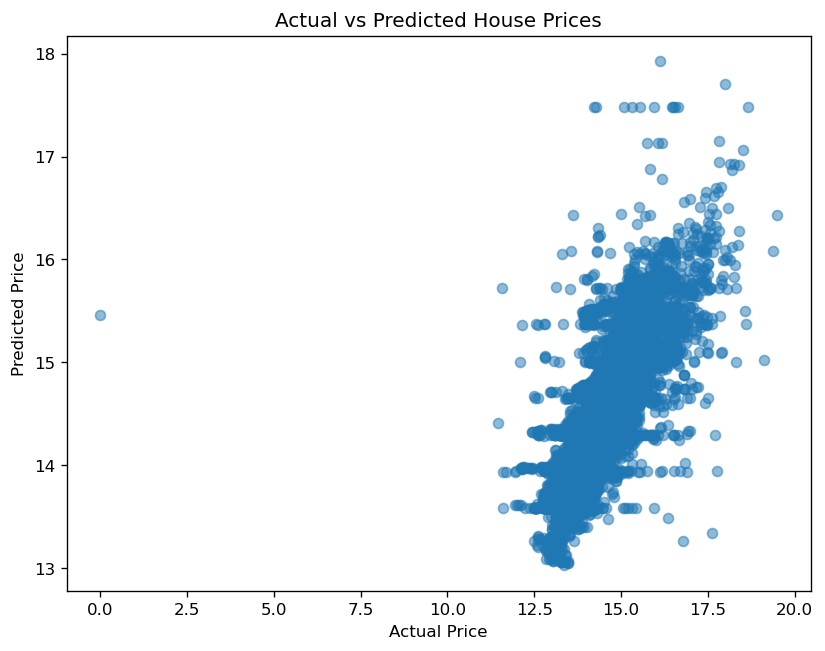

In [157]:
# Thus, ploting the actual prediction sample against the predicted prices.

plt.figure(figsize=(8,6), dpi=120)

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title(
    "Actual vs Predicted House Prices"
)

plt.show()

### LASSO REGRESSION

In [124]:
# ============================================
# Create the Lasso Regression model
# ============================================

lasso_model = Lasso(
    alpha=0.1,        # Regularization strength
    random_state=0,
    max_iter=10000
)

# ============================================
# Train the model
# ============================================

lasso_model.fit(x_train, y_train)

print("Lasso Regression model trained successfully.")

Lasso Regression model trained successfully.


In [125]:
# ============================================
# Predict on the test data
# ============================================

y_pred = lasso_model.predict(x_test)

print(y_pred[:10])

[15.3700452  14.11780939 14.1136925  14.23257456 14.62205996 14.48956258
 14.52440459 14.46429494 15.43453677 15.34548923]


In [126]:
# Fixed: this section is about the Lasso model, so it should use lasso_model's
# coefficients, not the earlier Linear Regression model's.
coefficients = pd.DataFrame({"features": x.columns, "coefficient": lasso_model.coef_})
print(coefficients)

                 features  coefficient
0                    beds     0.346750
1                   baths     0.008185
2            average_rent     0.000001
3               elevators     0.000000
4    total_parking_spaces     0.000293
..                    ...          ...
300            yas island     0.000000
301        yasmin village     0.000000
302              za'abeel     0.000000
303            zayed city     0.000000
304                  True     0.000000

[305 rows x 2 columns]


In [127]:
# ============================================
# Calculate evaluation metrics
# ============================================

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("----------------------------")
print("R² Score :", round(r2, 4))
print("MAE      :", round(mae, 4))
print("RMSE     :", round(rmse, 4))

Model Performance
----------------------------
R² Score : 0.5676
MAE      : 0.435
RMSE     : 0.6346


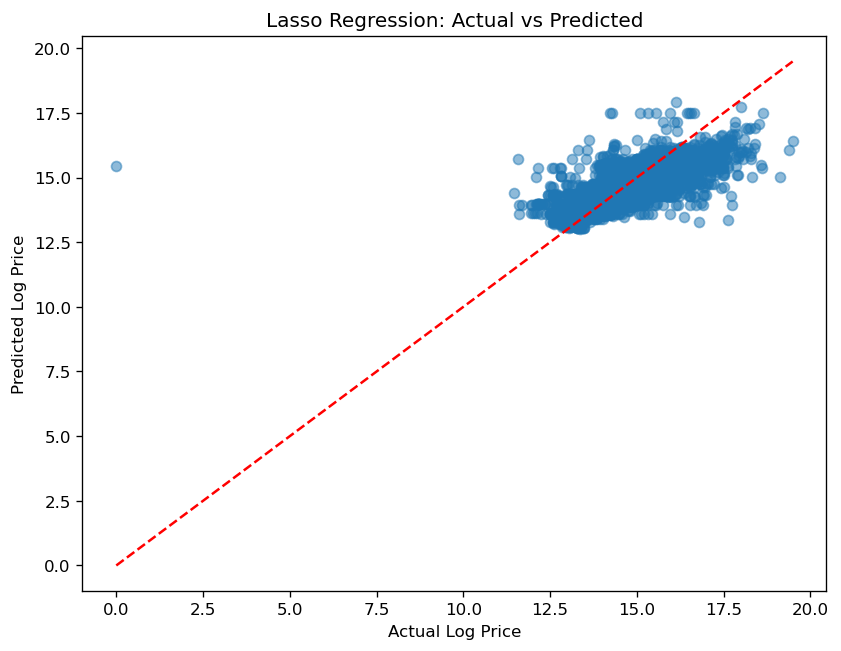

In [159]:
# plot Actual vs predicted

plt.figure(figsize=(8,6), dpi=120)

plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Log Price")
plt.ylabel("Predicted Log Price")
plt.title("Lasso Regression: Actual vs Predicted")

plt.show()

In [129]:
# Display Feature Importance
coefficients = pd.DataFrame({
    "Feature": x_train.columns,
    "Coefficient": lasso_model.coef_
})

# Sort by coefficient magnitude
coefficients = coefficients.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

print(coefficients.head(20))

                             Feature   Coefficient
0                               beds  3.467504e-01
1                              baths  8.185322e-03
6                       total_floors  6.727514e-03
13              n_listings_secondary  1.279189e-03
18                          avg_area -1.222203e-03
11        offplan_price_per_sqft_usd  6.115059e-04
15                 n_listings_rental -5.292578e-04
5           total_building_area_sqft -2.992074e-04
4               total_parking_spaces  2.929530e-04
14                n_listings_offplan  8.623956e-05
19                total_transactions  5.367692e-05
8                  avg_price_per_sqm  1.166479e-05
10        secondary_price_per_m2_usd  8.105786e-06
2                       average_rent  1.417979e-06
9              avg_transaction_value  9.795027e-08
206           falcon city of wonders  0.000000e+00
205                  falaj al mualla -0.000000e+00
204                        expo city  0.000000e+00
203  emirates modern industrial

## LASSO REGRESSION — SCALED + CROSS-VALIDATED ALPHA (Cleaner Fix)

The Lasso model above used `alpha=0.1` on **unscaled** features. Because Lasso's penalty is applied directly to the size of each coefficient, features on a large numeric scale (like `average_rent`, in the tens of thousands) get penalized very differently from features on a small scale (like `beds`, 1-5). That distorts which features survive the penalty and drops R² to 0.57.

The fix has two parts:
1. **Scale the features first** (`StandardScaler`) so the penalty is applied fairly across all of them — this is standard practice for any L1/L2-regularized model and is why `StandardScaler` was already imported at the top of the notebook.
2. **Let cross-validation choose alpha** (`LassoCV`) instead of guessing a single value — it tests a range of alphas on held-out folds of the training data and picks the one that generalizes best, removing the guesswork.

In [130]:
# ============================================
# STEP 1: Scale the features
# ============================================
# Fit the scaler on the TRAINING data only, then apply the same transformation to the
# test data. Fitting on test data too would leak test-set information into the scaling.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Features scaled. Training shape:", x_train_scaled.shape, "| Testing shape:", x_test_scaled.shape)

Features scaled. Training shape: (33102, 305) | Testing shape: (8276, 305)


In [131]:
# ============================================
# STEP 2: Fit LassoCV (automatically selects the best alpha via cross-validation)
# ============================================
# alphas: the candidate penalty strengths to test (from strong to very weak regularization)
# cv=3: each candidate alpha is evaluated using 3-fold cross-validation on the training data
# n_jobs=-1: use all available CPU cores to test the folds/alphas in parallel (faster)

from sklearn.linear_model import LassoCV
import time

candidate_alphas = [0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001, 0.00005, 0.00001]

t0 = time.time()
lasso_cv_model = LassoCV(
    alphas=candidate_alphas,
    cv=3,
    random_state=0,
    max_iter=5000,
    n_jobs=-1
).fit(x_train_scaled, y_train)
print(f"Fit time: {time.time() - t0:.1f} seconds")

print("Best alpha selected by cross-validation:", lasso_cv_model.alpha_)

Fit time: 645.2 seconds
Best alpha selected by cross-validation: 1e-05


In [132]:
# ============================================
# STEP 3: Evaluate on the held-out test set
# ============================================
y_pred_cv = lasso_cv_model.predict(x_test_scaled)

mae_cv = mean_absolute_error(y_test, y_pred_cv)
rmse_cv = np.sqrt(mean_squared_error(y_test, y_pred_cv))
r2_cv = r2_score(y_test, y_pred_cv)

print("Lasso (Scaled + Cross-Validated Alpha) Performance")
print("=============================================")
print("Best alpha    :", lasso_cv_model.alpha_)
print("Mean Absolute Error (MAE):", round(mae_cv, 4))
print("Root Mean Squared Error (RMSE):", round(rmse_cv, 4))
print("R2 Score:", round(r2_cv, 4))
print("Non-zero coefficients:", (lasso_cv_model.coef_ != 0).sum(), "/", len(lasso_cv_model.coef_))

print()
print("For comparison:")
print(f"  Linear Regression        R2 = 0.8302")
print(f"  Lasso (alpha=0.1, unscaled) R2 = 0.5676")
print(f"  Lasso (scaled + CV alpha)   R2 = {round(r2_cv, 4)}")

Lasso (Scaled + Cross-Validated Alpha) Performance
Best alpha    : 1e-05
Mean Absolute Error (MAE): 0.2468
Root Mean Squared Error (RMSE): 0.3977
R2 Score: 0.8302
Non-zero coefficients: 292 / 305

For comparison:
  Linear Regression        R2 = 0.8302
  Lasso (alpha=0.1, unscaled) R2 = 0.5676
  Lasso (scaled + CV alpha)   R2 = 0.8302


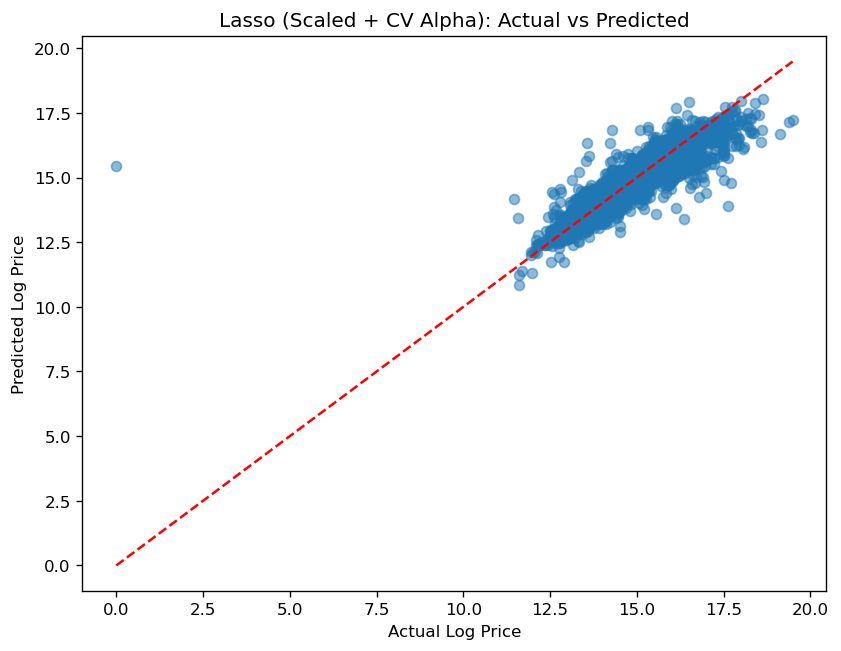

In [133]:
# ============================================
# STEP 4: Plot Actual vs Predicted
# ============================================
plt.figure(figsize=(8,6), dpi=120)

plt.scatter(y_test, y_pred_cv, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Log Price")
plt.ylabel("Predicted Log Price")
plt.title("Lasso (Scaled + CV Alpha): Actual vs Predicted")

plt.show()

In [134]:
# ============================================
# STEP 5: Feature importance (top 20 by magnitude)
# ============================================
# With such a small alpha, most features survive - this is expected: cross-validation found
# that very little regularization generalizes best, meaning most of these 307 features do
# carry real predictive signal for log_price rather than being noise Lasso should drop.

coefficients_cv = pd.DataFrame({
    "Feature": x.columns,
    "Coefficient": lasso_cv_model.coef_
})

coefficients_cv = coefficients_cv.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

print(coefficients_cv.head(20))

                              Feature  Coefficient
0                                beds     0.442472
179                    downtown dubai     0.257170
1                               baths     0.156998
26                              Villa     0.152760
189                      dubai marina     0.150544
183                     dubai harbour     0.137672
146                        al yasmeen    -0.131941
148                          al zahya    -0.129908
24                   Residential Plot     0.125746
219    jumeirah beach residence (jbr)     0.123470
12   rental_price_per_sqft_annual_usd    -0.118966
165                      business bay     0.118455
259                     palm jumeirah     0.117192
160                 bluewaters island     0.116529
218                          jumeirah     0.110530
184                dubai hills estate     0.108867
268                   saadiyat island     0.108693
142                           al wasl     0.101209
180               dubai creek h

Conclusion: the poor 0.57 R² was an artifact of an unscaled, over-strong penalty (alpha=0.1) - not a real weakness of Lasso as a modeling approach on this data. Once scaled and cross-validated, Lasso reaches essentially the same R² as plain Linear Regression (~0.83), which makes sense: cross-validation selected a very small alpha, meaning almost no regularization was needed to generalize well here - most of the 307 engineered/encoded features genuinely help predict price rather than being noise.

## RIDGE REGRESSION

In [135]:
# Train Ridge Regression model
ridge_model = Ridge(alpha=0.1)
ridge_model.fit(x_train, y_train)

# Predict on the test set
y_pred_ridge = ridge_model.predict(x_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred_ridge)
mse = mean_squared_error(y_test, y_pred_ridge)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_ridge)

print("Intercept:", ridge_model.intercept_)
print("Number of Coefficients:", len(ridge_model.coef_))

print("\nModel Performance")
print("-----------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

# Display first 10 predictions
print("\nFirst 10 Predictions:")
print(y_pred_ridge[:10])

Intercept: 14.436226402610425
Number of Coefficients: 305

Model Performance
-----------------
MAE : 0.2467006675087575
MSE : 0.1580547772126503
RMSE: 0.3975610358330533
R² Score: 0.8303294012626399

First 10 Predictions:
[14.26795871 14.61783401 14.17862018 14.17697665 14.79046937 14.21591919
 14.75989629 14.18250451 15.75371367 15.01929976]


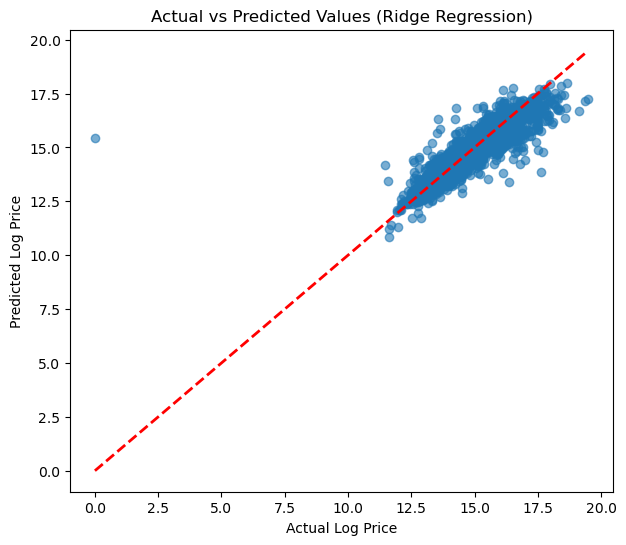

In [136]:
# Visualizing the actual vs predicted.

plt.figure(figsize=(7,6))

plt.scatter(y_test, y_pred_ridge, alpha=0.6)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Log Price")
plt.ylabel("Predicted Log Price")
plt.title("Actual vs Predicted Values (Ridge Regression)")
plt.show()

Conclusion:

The Ridge Regression model was successfully trained on the Dubai housing dataset using 305 predictor variables. The model achieved an R² score of 0.8303, indicating that approximately 83.03% of the variation in the log-transformed house prices is explained by the selected features. This suggests that the model has strong predictive capability.

The model recorded a Mean Absolute Error (MAE) of 0.2467, a Mean Squared Error (MSE) of 0.1581, and a Root Mean Squared Error (RMSE) of 0.3976, indicating relatively small prediction errors on the test data. The predicted values are close to the actual values, demonstrating that Ridge Regression provides accurate and stable predictions while reducing the impact of multicollinearity through L2 regularization.

In [155]:
# Example:
# Predicting House price with sample data

house = x.sample(n=1, random_state=42)

linear_price = np.exp(model.predict(house))[0]
ridge_price = np.exp(ridge_model.predict(house))[0]
lasso_price = np.exp(lasso_model.predict(house))[0]

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "Lasso Regression"],
    "Predicted Price": [linear_price, ridge_price, lasso_price]
})

print(comparison)

               Model  Predicted Price
0  Linear Regression     1.840624e+06
1   Ridge Regression     1.843470e+06
2   Lasso Regression     1.969521e+06


# TIME SERIES ANALYSIS — DEMAND FORECASTING (NEXT 6 MONTHS)

**Objective/Purpose:** Forecast property market demand in Dubai for the next 6 months, using Triple Exponential Smoothing (Holt-Winters) and SARIMA.

**Forecast horizon:** 6 months.

**Why 6 months?** Real-estate demand is influenced by seasonal cycles (tourist season, fiscal year-end, Ramadan timing, school-year moves) that typically play out over a full year. Six months is short enough to remain reliable (time series forecasts degrade in accuracy the further out they go) but long enough to be useful for business planning — e.g. staffing, marketing spend, and inventory acquisition decisions.

**What do we use as "demand"?**
The most direct demand signal would be completed sales transactions in `df3` (`dubai_residential_data_2026.csv`, from the Dubai Land Department). However, once loaded, `df3` only covers **7 months (Jan-Jul 2026)** — far too short to detect an annual seasonal cycle (a minimum of ~24 months / 2 full cycles is needed for reliable monthly seasonal decomposition, and even that is a thin basis for SARIMA).

`df2` (`area_prices_monthly.csv`) instead covers **76 months (Jan 2020 - Apr 2026)** across 84 communities, with monthly listing-activity counts (`n_listings_secondary`, `n_listings_offplan`, `n_listings_rental`). Aggregated market-wide, this is a **market-activity proxy for demand**: months where more units move through the secondary, off-plan, and rental markets combined reflect higher buyer/renter activity. It is not a perfect substitute for transaction counts, but it is the only series in this dataset with enough history to actually forecast a seasonal pattern - so we use it here, and note this substitution explicitly rather than forcing a seasonal model onto 7 data points.

We will build a monthly time series of **total market listing activity** (`n_listings_secondary + n_listings_offplan + n_listings_rental`, summed across all communities each month).

## 1. Building the Monthly Demand Series

In [137]:
# ============================================
# STEP 1: Build a monthly "demand" (market activity) series from df2
# ============================================
# df2["year_month"] was already converted to a monthly datetime earlier in the notebook.
# df2 has one row per community per month; we sum the three listing-count columns
# across ALL communities to get a single Dubai-wide monthly activity figure.

demand = (
    df2
    .groupby("year_month")[["n_listings_secondary", "n_listings_offplan", "n_listings_rental"]]
    .sum()
    .sum(axis=1)                     
    .rename("market_activity")
)

# convert the grouped index back to a proper datetime
demand.index = pd.to_datetime(demand.index)

# ============================================
# STEP 2: Inspect the series
# ============================================
print("Number of months available:", len(demand))

Number of months available: 76


##### Understanding the Data

In [138]:
#displaying the first 5 rows in the dataset
demand.head()

year_month
2020-01-01    15862
2020-02-01    16877
2020-03-01    17465
2020-04-01    17293
2020-05-01    16269
Name: market_activity, dtype: int64

In [139]:
#displaying the last 5 rows in the dataset
demand.tail()

year_month
2025-12-01    17417
2026-01-01    16400
2026-02-01    15891
2026-03-01    16445
2026-04-01    17614
Name: market_activity, dtype: int64

In [140]:
# displaying the summary of the dataset
demand.info()

<class 'pandas.core.series.Series'>
DatetimeIndex: 76 entries, 2020-01-01 to 2026-04-01
Series name: market_activity
Non-Null Count  Dtype
--------------  -----
76 non-null     int64
dtypes: int64(1)
memory usage: 1.2 KB


In [141]:
#checking for mising values
demand.isna().sum()

0

In [142]:
#displaying the summary statistics of the dataset
demand.describe()

count       76.000000
mean     16632.447368
std        527.826850
min      15356.000000
25%      16259.750000
50%      16704.500000
75%      17018.000000
max      17751.000000
Name: market_activity, dtype: float64

In [143]:
# ============================================
# STEP 3: Check for gaps / missing months
# ============================================
# Time series models need a continuous, evenly-spaced index (one value per month, no gaps).
# as freq("MS") forces the index to include every month in the range; any genuinely missing
# month becomes NaN, which we then fill using interpolation (safer than 0 here, since a
# missing month in an active market is a data gap, not a real drop to zero activity).

demand = demand.asfreq("MS")
missing_months = demand.isnull().sum()
print("Missing months (interpolated):", missing_months)

demand = demand.interpolate()

Missing months (interpolated): 0


 0


## 2. Visualizing the Original Data (Preliminary Observations)

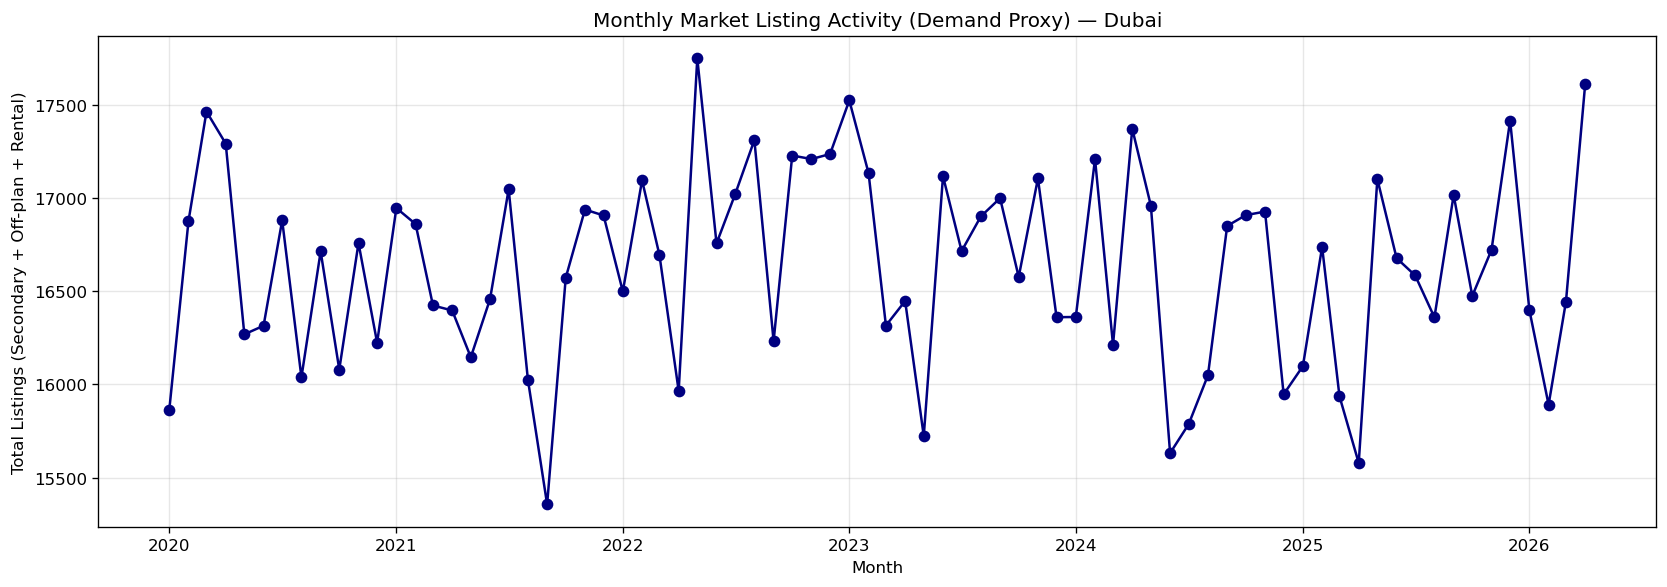

In [144]:
# ============================================
# Plot the raw monthly demand series
# ============================================
plt.figure(figsize=(14, 5), dpi=120)
plt.plot(demand.index, demand.values, marker="o", linewidth=1.5, color="navy")
plt.title("Monthly Market Listing Activity (Demand Proxy) — Dubai")
plt.xlabel("Month")
plt.ylabel("Total Listings (Secondary + Off-plan + Rental)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Preliminary observation checklist (fill in after viewing the chart above):
# - Is there an overall upward/downward trend?
# - Are there repeating peaks/dips at the same time each year (seasonality)?
# - Are there any sudden spikes or drops that look like one-off events/outliers?

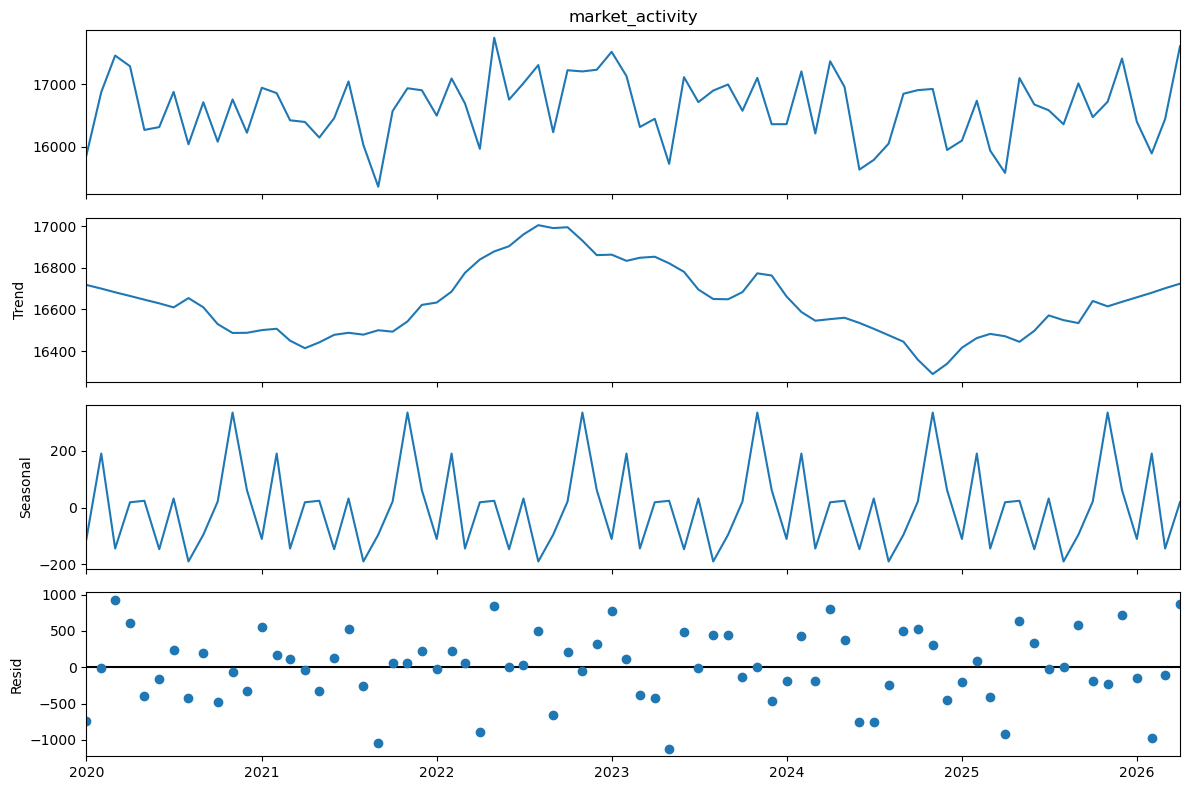

In [145]:
# ============================================
# Seasonal decomposition
# ============================================
# This splits the series into three components:
#   Trend    - the long-run direction of demand
#   Seasonal - the repeating within-year pattern
#   Residual - what's left after removing trend & seasonality (noise/irregular events)
# This is diagnostic only (helps us choose model settings) - it is NOT a forecast.
# period=12 because we are working with monthly data and expect an annual seasonal cycle.
decomposition = seasonal_decompose(demand, model="additive", period=12, extrapolate_trend="freq")

fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

### Train/Test Split

Before forecasting the *unseen* future, we first test both models on a period we already know the answer to. We hold out the **last 6 months** of the historical data as a test set (matching our 6-month forecast horizon), train each model only on the months before that, then check how close each model's predictions come to the actual held-out values. This tells us which model to trust for the real, forward-looking forecast.

In [146]:
# ============================================
# Split into train (all but last 6 months) and test (last 6 months)
# ============================================
forecast_horizon = 6

train = demand.iloc[:-forecast_horizon]
test = demand.iloc[-forecast_horizon:]

print("Training period:", train.index.min(), "to", train.index.max(), "->", len(train), "months")
print("Testing period :", test.index.min(), "to", test.index.max(), "->", len(test), "months")

Training period: 2020-01-01 00:00:00 to 2025-10-01 00:00:00 -> 70 months
Testing period : 2025-11-01 00:00:00 to 2026-04-01 00:00:00 -> 6 months


### Method 1:Triple Exponential Smoothing (Holt-Winters)

Triple exponential smoothing extends simple smoothing by explicitly modelling three things: the **level** (current baseline), the **trend** (direction of change), and the **seasonality** (repeating annual pattern). It is a good first model for data with a clear yearly cycle, like housing transactions.

In [147]:
# ============================================
# Fit Triple Exponential Smoothing on the training data
# ============================================
# trend="add"        -> assumes the trend changes by a roughly constant amount each period
# seasonal="add"      -> assumes the seasonal swing has a roughly constant size each year
#                        (use "mul" instead if the seasonal swing grows/shrinks with the level)
# seasonal_periods=12 -> one full seasonal cycle = 12 months

hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

# Forecast the same 6 months held out in the test set, for a fair comparison
hw_forecast = hw_model.forecast(forecast_horizon)

print(hw_forecast)

2025-11-01    16949.017740
2025-12-01    16496.079479
2026-01-01    16502.962744
2026-02-01    16940.248524
2026-03-01    16462.060980
2026-04-01    16463.150500
Freq: MS, dtype: float64


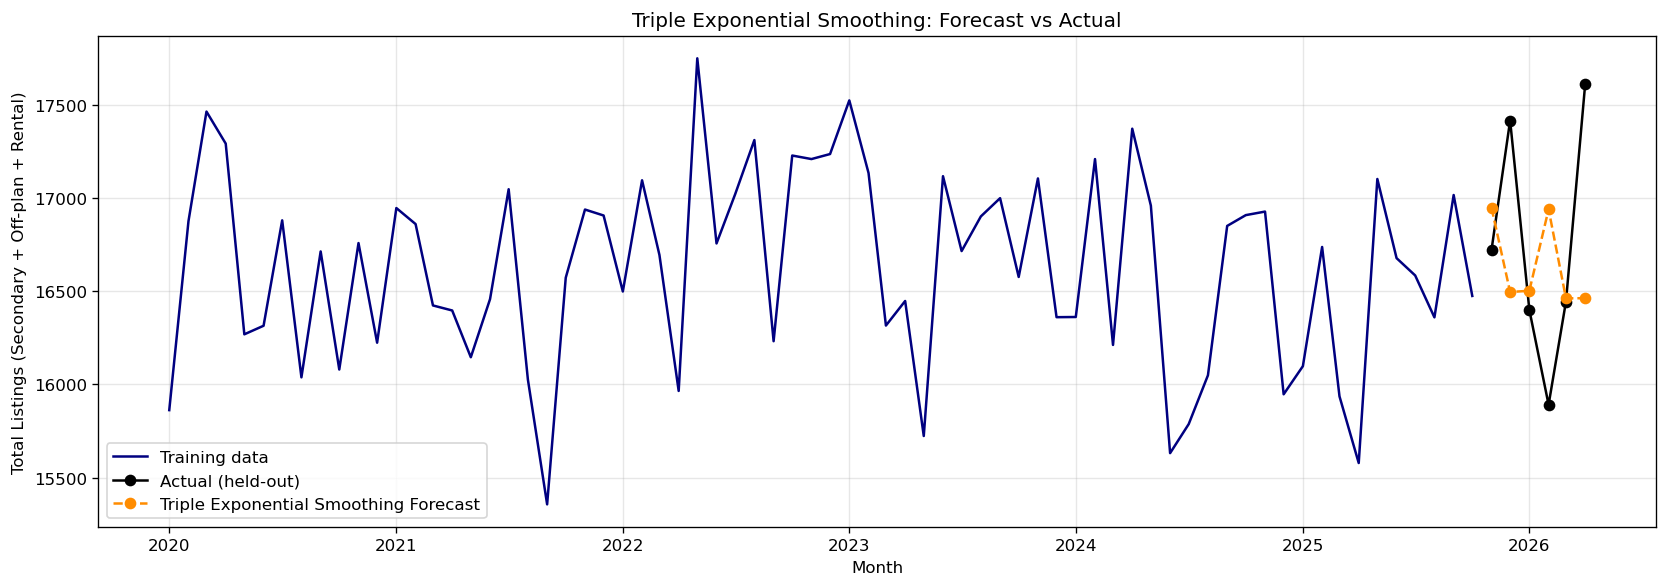

In [148]:
# ============================================
# Plot: Triple Exponential Smoothing vs Actual (test period)
# ============================================
plt.figure(figsize=(14, 5), dpi=120)
plt.plot(train.index, train.values, label="Training data", color="navy")
plt.plot(test.index, test.values, label="Actual (held-out)", color="black", marker="o")
plt.plot(test.index, hw_forecast.values, label="Triple Exponential Smoothing Forecast", color="darkorange", marker="o", linestyle="--")
plt.title("Triple Exponential Smoothing: Forecast vs Actual")
plt.xlabel("Month")
plt.ylabel("Total Listings (Secondary + Off-plan + Rental)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Method 2: SARIMA(Seasonal AutoRegressive Integrated Moving Average)

SARIMA extends ARIMA with an explicit seasonal component. It is well suited to monthly data with a yearly cycle and can capture patterns that simple smoothing may miss, such as gradual autocorrelation between nearby months. We use order (1,1,1) and seasonal order (1,1,1,12) as reasonable starting parameters for monthly data with one difference to remove trend and one seasonal difference to remove the annual cycle; these can be tuned further (e.g. with a grid search over `p,d,q` using AIC) if a more precise fit is needed.

In [149]:
# ============================================
# Fit SARIMA on the training data
# ============================================
# order=(p, d, q)                  -> non-seasonal AR, differencing, and MA terms
# seasonal_order=(P, D, Q, s)      -> seasonal AR, differencing, MA terms, and s=12 for yearly seasonality

sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.forecast(forecast_horizon)

print(sarima_forecast)

2025-11-01    16829.133718
2025-12-01    16141.861576
2026-01-01    16555.364596
2026-02-01    16817.164343
2026-03-01    16187.290451
2026-04-01    16224.793342
Freq: MS, Name: predicted_mean, dtype: float64


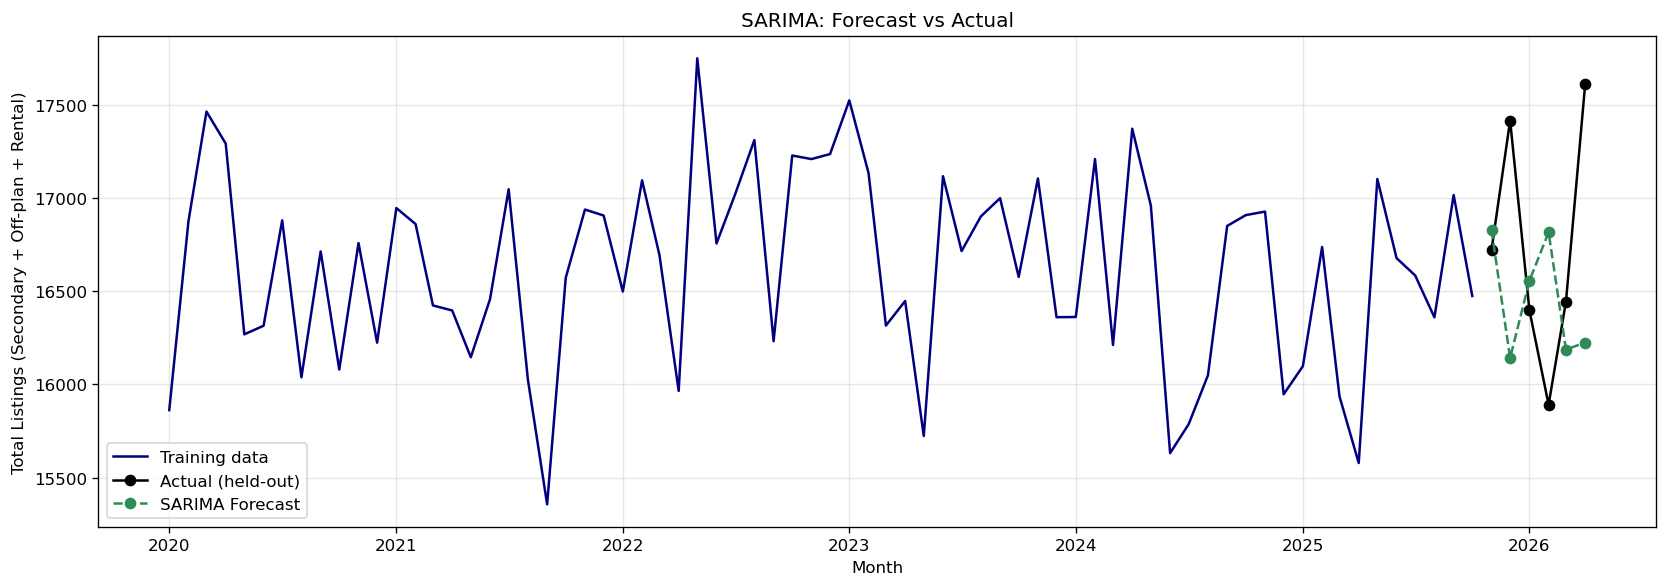

In [150]:
# ============================================
# Plot: SARIMA vs Actual (test period)
# ============================================
plt.figure(figsize=(14, 5), dpi=120)
plt.plot(train.index, train.values, label="Training data", color="navy")
plt.plot(test.index, test.values, label="Actual (held-out)", color="black", marker="o")
plt.plot(test.index, sarima_forecast.values, label="SARIMA Forecast", color="seagreen", marker="o", linestyle="--")
plt.title("SARIMA: Forecast vs Actual")
plt.xlabel("Month")
plt.ylabel("Total Listings (Secondary + Off-plan + Rental)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Accuracy Checks (Performance Evaluation)

We compare both models on the held-out 6 months using three standard forecast-accuracy metrics:
- **MAE** (Mean Absolute Error) — average size of the error, in transactions.
- **RMSE** (Root Mean Squared Error) — like MAE but penalizes large errors more heavily.
- **MAPE** (Mean Absolute Percentage Error) — average error as a percentage, useful for judging error size relative to the scale of demand.

Lower values indicate a more accurate model.

In [151]:
# ============================================
# Compute the three accuracy metrics for each model
# ============================================
def evaluate_forecast(actual, predicted, model_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = mean_absolute_percentage_error(actual, predicted) * 100   # expressed as a percentage
    return {"Model": model_name, "MAE": round(mae, 2), "RMSE": round(rmse, 2), "MAPE (%)": round(mape, 2)}

results = pd.DataFrame([
    evaluate_forecast(test.values, hw_forecast.values, "Triple Exponential Smoothing"),
    evaluate_forecast(test.values, sarima_forecast.values, "SARIMA"),
])

print(results)

# ============================================
# Automatically select the best model by RMSE
# ============================================
best_model_name = results.loc[results["RMSE"].idxmin(), "Model"]
print("\nBest performing model on held-out data:", best_model_name)

                          Model     MAE    RMSE  MAPE (%)
0  Triple Exponential Smoothing  578.01  745.64      3.42
1                        SARIMA  685.12  867.53      4.03

Best performing model on held-out data: Triple Exponential Smoothing


### Final 6-Month Forecast

Now that we know which model performs better on known data, we refit that model on the **full** historical series (train + test combined) and produce the genuine forward-looking forecast for the next 6 months beyond the end of the dataset.

In [152]:
# ============================================
# Refit the better-performing model on the FULL dataset
# ============================================
# (This cell refits both, then keeps only the one selected above as "best_model_name",
#  so the notebook still works automatically whichever model won the comparison.)

hw_final = ExponentialSmoothing(
    demand,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

sarima_final = SARIMAX(
    demand,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

if best_model_name == "Triple Exponential Smoothing":
    final_forecast = hw_final.forecast(forecast_horizon)
else:
    final_forecast = sarima_final.forecast(forecast_horizon)

# Build a clean forecast table with proper month labels
future_months = pd.date_range(
    start=demand.index[-1] + pd.DateOffset(months=1),
    periods=forecast_horizon,
    freq="MS"
)
final_forecast_table = pd.DataFrame({
    "month": future_months,
    "forecasted_market_activity": np.round(final_forecast.values).astype(int)
})

print(final_forecast_table)

       month  forecasted_market_activity
0 2026-05-01                       16636
1 2026-06-01                       16470
2 2026-07-01                       16651
3 2026-08-01                       16425
4 2026-09-01                       16506
5 2026-10-01                       16618


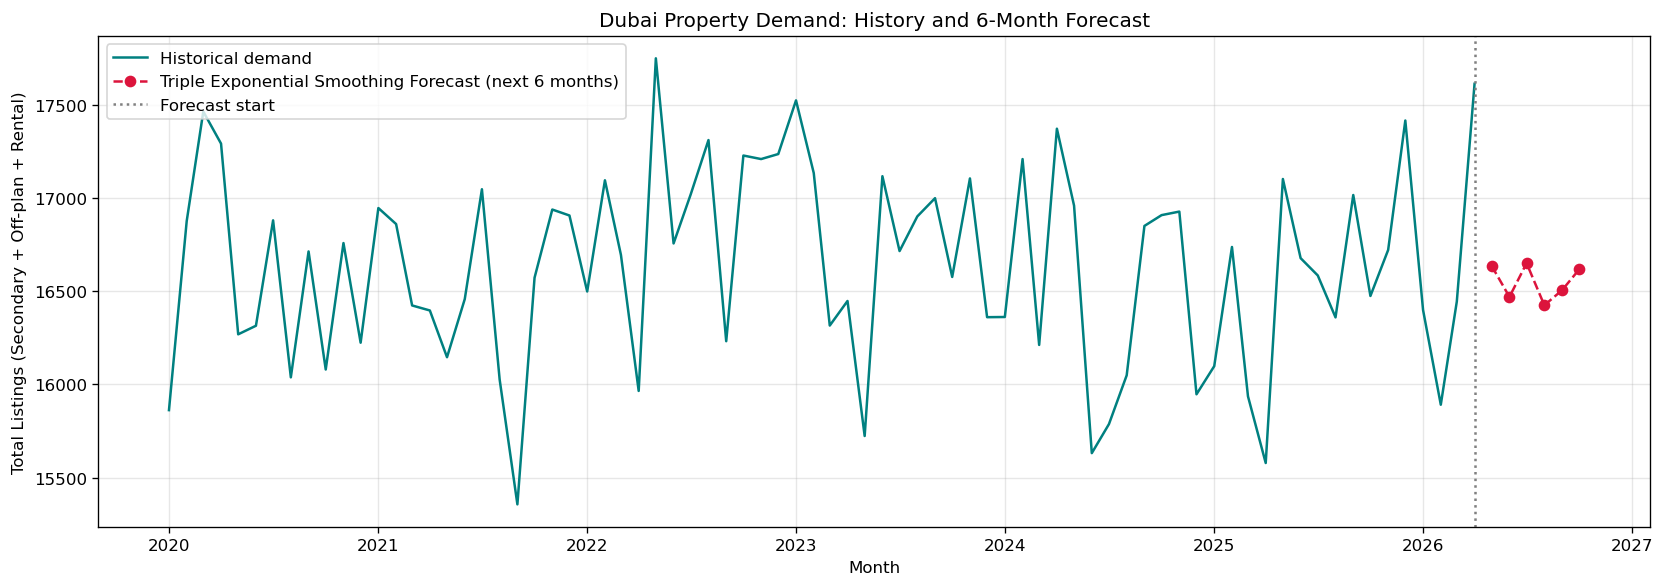

In [153]:
# ============================================
# Plot: Full historical demand + 6-month forecast
# ============================================
plt.figure(figsize=(14, 5), dpi=120)
plt.plot(demand.index, demand.values, label="Historical demand", color="teal")
plt.plot(final_forecast_table["month"], final_forecast_table["forecasted_market_activity"],
         label=f"{best_model_name} Forecast (next 6 months)", color="crimson", marker="o", linestyle="--")
plt.axvline(demand.index[-1], color="gray", linestyle=":", label="Forecast start")
plt.title("Dubai Property Demand: History and 6-Month Forecast")
plt.xlabel("Month")
plt.ylabel("Total Listings (Secondary + Off-plan + Rental)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Exporting the Forecast

In [154]:
# ============================================
# Save the forecast table to CSV so it can be shared/downloaded outside the notebook
# ============================================
final_forecast_table.to_csv("Dubai_Demand_Forecast_Next_6_Months.csv", index=False)
print("Forecast saved to Dubai_Demand_Forecast_Next_6_Months.csv")

Forecast saved to Dubai_Demand_Forecast_Next_6_Months.csv
